# Práctica 2 — Modelos Avanzados de Aprendizaje Automático I (Curso 2026/27)
## Sistema Robusto de Clasificación Multiclase frente a Deriva Temporal de Sensores (*Electronic Nose*)

**Conjunto de datos:** *UCI Gas Sensor Array Drift Dataset at Different Concentrations* (Vergara et al., 2012; 13.910 instancias, 16 sensores MOX × 8 características dinámicas/estáticas = 128 predictores sensoriales + identificador temporal de *batch*, 10 *batches* a lo largo de 36 meses, 6 clases de gases).  
**Semilla global de reproducibilidad:** `104` (fijada en todas las particiones, inicializaciones y algoritmos estocásticos).  
**Ejecución autónoma:** Este *notebook* se ejecuta íntegramente de principio a fin sin requerir modificaciones ni parámetros externos, reutilizando la arquitectura modular de `src/` y generando automáticamente todas las tablas (`results/`) y figuras a 300 DPI (`figures/`) incluidas en `Memoria_Practica2.pdf`.

In [1]:
const BASE_DIR    = isfile(joinpath((@__DIR__), "Project.toml")) ? (@__DIR__) : pwd()
using Pkg
Pkg.activate(BASE_DIR)

using Random, Statistics, StatsBase, DataFrames, CSV, JSON, Printf

const SEED = 104
Random.seed!(SEED)

const DATA_DIR    = joinpath(BASE_DIR, "gas+sensor+array+drift+dataset+at+different+concentrations")
const RESULTS_DIR = joinpath(BASE_DIR, "results")
const FIGURES_DIR = joinpath(BASE_DIR, "figures")
mkpath(RESULTS_DIR)
mkpath(FIGURES_DIR)

include(joinpath(BASE_DIR, "src", "data_utils.jl"))
include(joinpath(BASE_DIR, "src", "mlj_wrappers.jl"))
include(joinpath(BASE_DIR, "src", "experiments.jl"))
include(joinpath(BASE_DIR, "src", "visualizations.jl"))

println("Entorno Julia $(VERSION) cargado correctamente | Semilla global = $(SEED)")

Entorno Julia 1.11.2 cargado correctamente | Semilla global = 104


---
## 1. Carga, Unificación y Descripción del Conjunto de Datos

Unificamos los 10 ficheros `batch1.dat` … `batch10.dat` en un único `DataFrame` consolidado preservando el orden cronológico de adquisición (Meses 1 a 36). Cada registro en formato LIBSVM extendido (`clase;concentración 1:v1 ... 128:v128`) aporta:
- **128 características numéricas sensoriales** organizadas en bloques de 8 por cada sensor MOX ($S_1, \dots, S_{16}$): variación máxima $DR_j$, variación normalizada $|DR|_j$, tres medias móviles exponenciales en transitorio creciente ($EMAi_{\alpha}, \alpha \in \{0.001, 0.01, 0.1\}$) y tres en transitorio decreciente ($EMAd_{\alpha}$).
- **Identificador temporal `batch`** ($1 \dots 10$), que completa las **129 variables** descritas en el enunciado. Se utiliza exclusivamente para estructurar la partición temporal *holdout* y la validación cruzada *batch-wise*, excluyéndose de la matriz predictora $X$ para impedir atajos espurios no estacionarios.
- **Metadato físico `concentration` (ppmv)**: retenido únicamente para auditoría exploratoria y excluido de $X$ porque en un despliegue real la concentración es desconocida y sus rangos experimentales difieren por analito (p. ej. Tolueno $\le 230$ ppmv frente a Amoníaco/Acetona hasta $1000$ ppmv), lo que induciría *target leakage* experimental.

In [2]:
df, X_raw, batches, classes, concs, explicit_missing = load_gas_drift_dataset(DATA_DIR)
n_rows, n_feat = size(X_raw)
n_batches = length(unique(batches))
n_classes = length(unique(classes))

desc_df = DataFrame(
    Propiedad = [
        "Número total de instancias",
        "Variables documentadas (128 sensoriales + batch)",
        "Predictores empleados en X",
        "Variables excluidas de X (anti-leakage)",
        "Número de batches temporales",
        "Número de clases (gases)"
    ],
    Valor = [
        string(n_rows),
        string(n_feat + 1),
        string(n_feat),
        "batch (particionado temporal) y concentration (ppmv, metadato)",
        "$n_batches (Meses 1 a 36)",
        "$n_classes: " * join(["$c=$(GAS_NAMES[c])" for c in 1:6], ", ")
    ]
)
display(desc_df)

Propiedad,Valor
Número total de instancias,13910
Variables documentadas (128 sensoriales + batch),129
Predictores empleados en X,128
Variables excluidas de X (anti-leakage),"batch (particionado temporal) y concentration (ppmv, metadato)"
Número de batches temporales,10 (Meses 1 a 36)
Número de clases (gases),"6: 1=Ethanol, 2=Ethylene, 3=Ammonia, 4=Acetaldehyde, 5=Acetone, 6=Toluene"


**Conclusiones parciales (Fase 1):** El dataset consolidado reúne exactamente **13.910 instancias** y **129 variables** (128 predictores continuos de los 16 sensores MOX más el índice de *batch*), distribuidas en **10 bloques temporales** y **6 clases químicas**. La separación explícita entre predictores físicos ($X \in \mathbb{R}^{13910 \times 128}$) y metadatos experimentales (`batch`, `concentration`) garantiza ausencia de *data leakage* de dominio desde el origen.

---
## 2. Análisis Exploratorio Inicial y Deriva Temporal Preliminar

Inspeccionamos el volumen muestral por *batch*, el balance de clases a lo largo de los 36 meses y la evolución temporal tanto de la sensibilidad estática media ($DR$) como de la distancia distribucional de Kolmogorov-Smirnov ($KS$) de cada *batch* frente al estado inicial calibrado (*Batch 1*).

Batch,Periodo,Muestras,Pct_Total,DR_Medio_kOhm,KS_Medio_vs_B1
1,Meses 1-2,445,3.20,36.60,0.000
2,"Meses 3-4, 8-10",1244,8.94,37.69,0.273
3,Meses 11-13,1586,11.40,29.06,0.343
4,Meses 14-15,161,1.16,24.41,0.461
5,Mes 16,197,1.42,35.82,0.525
6,Meses 17-20,2300,16.53,19.90,0.356
7,Mes 21,3613,25.97,18.13,0.318
8,Meses 22-23,294,2.11,11.61,0.469
9,"Meses 24, 30",470,3.38,9.86,0.470
10,Mes 36,3600,25.88,19.78,0.226


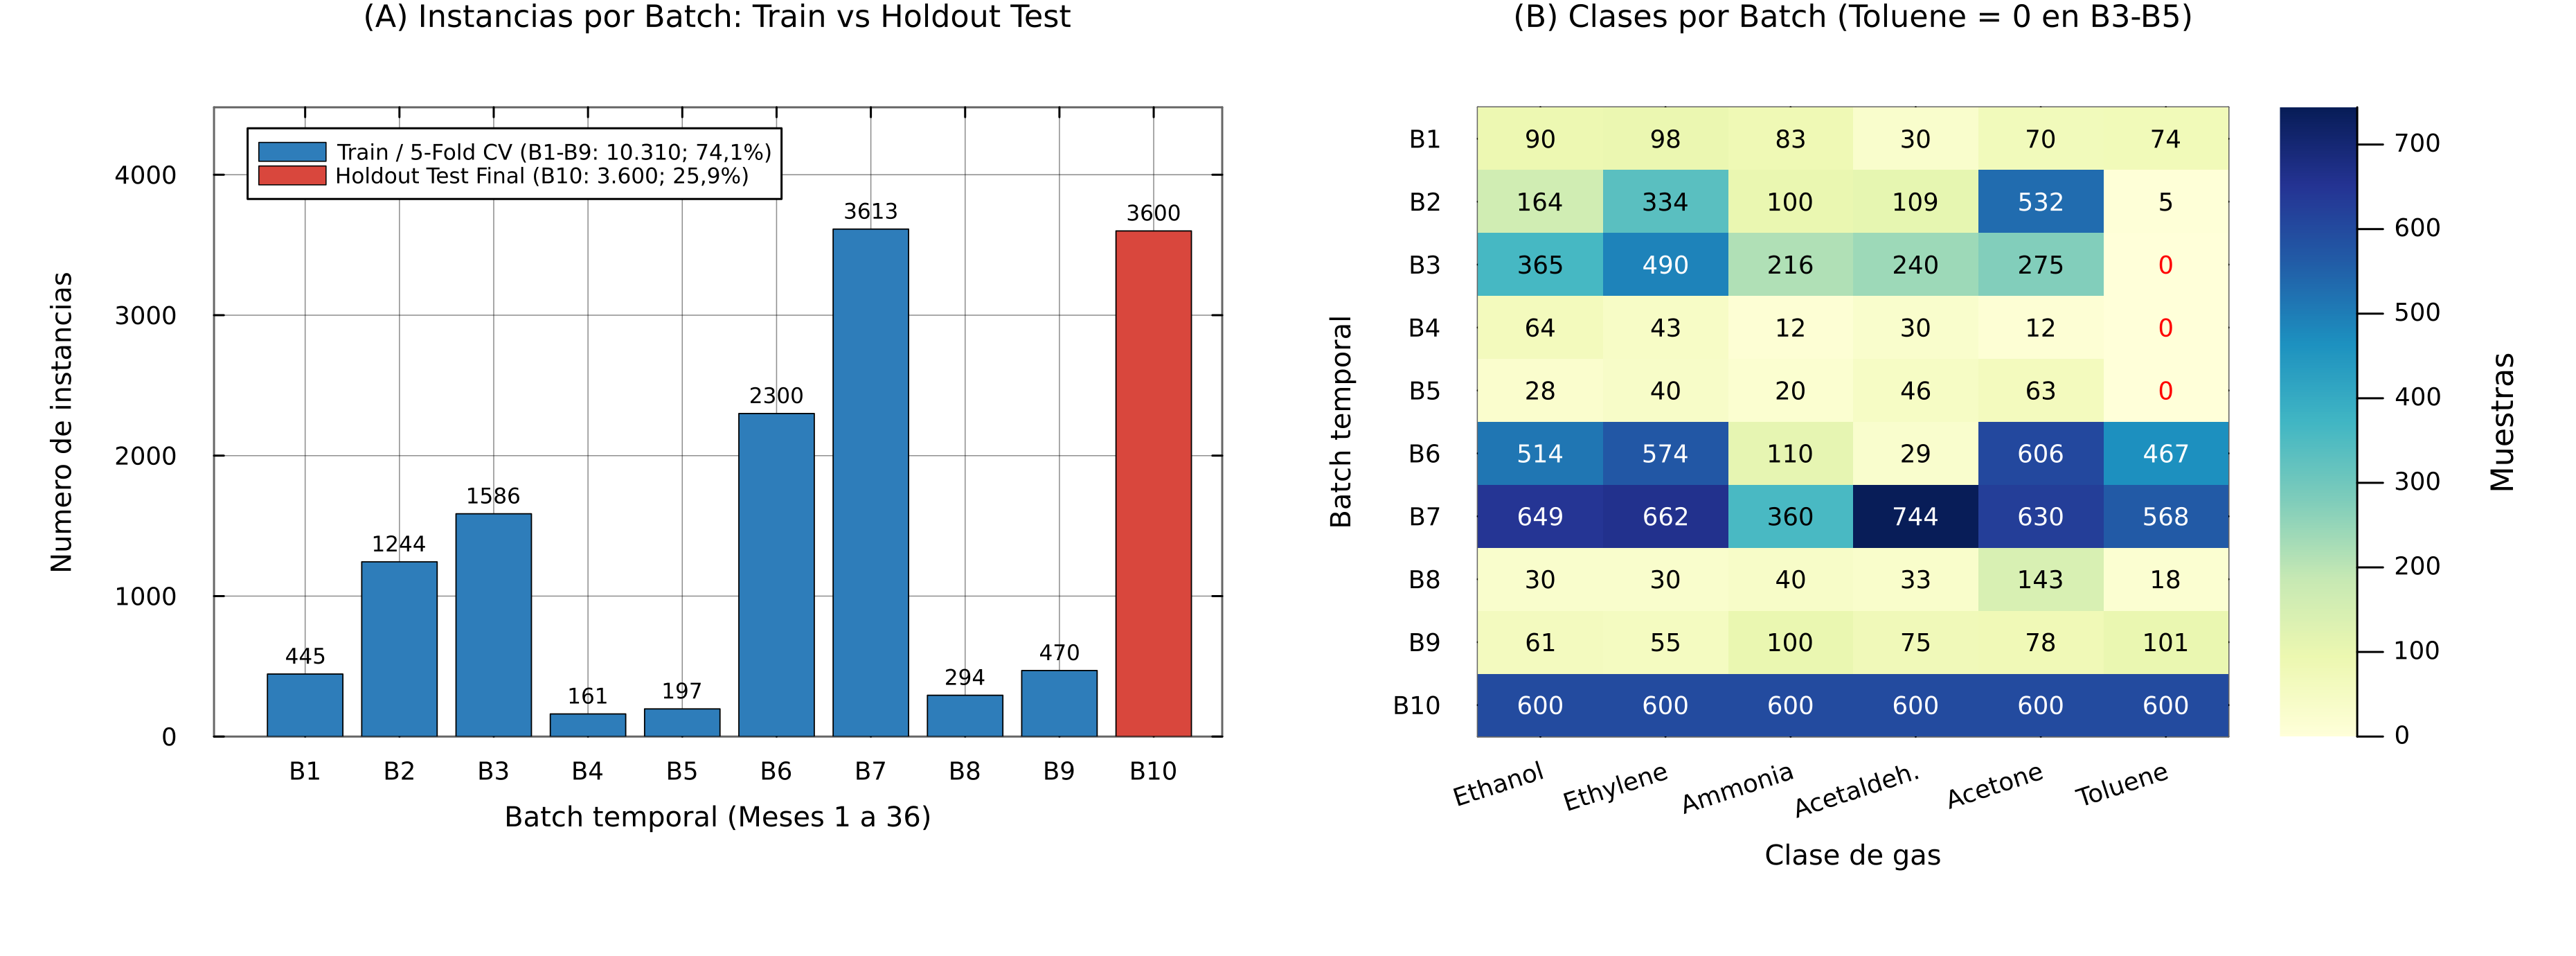

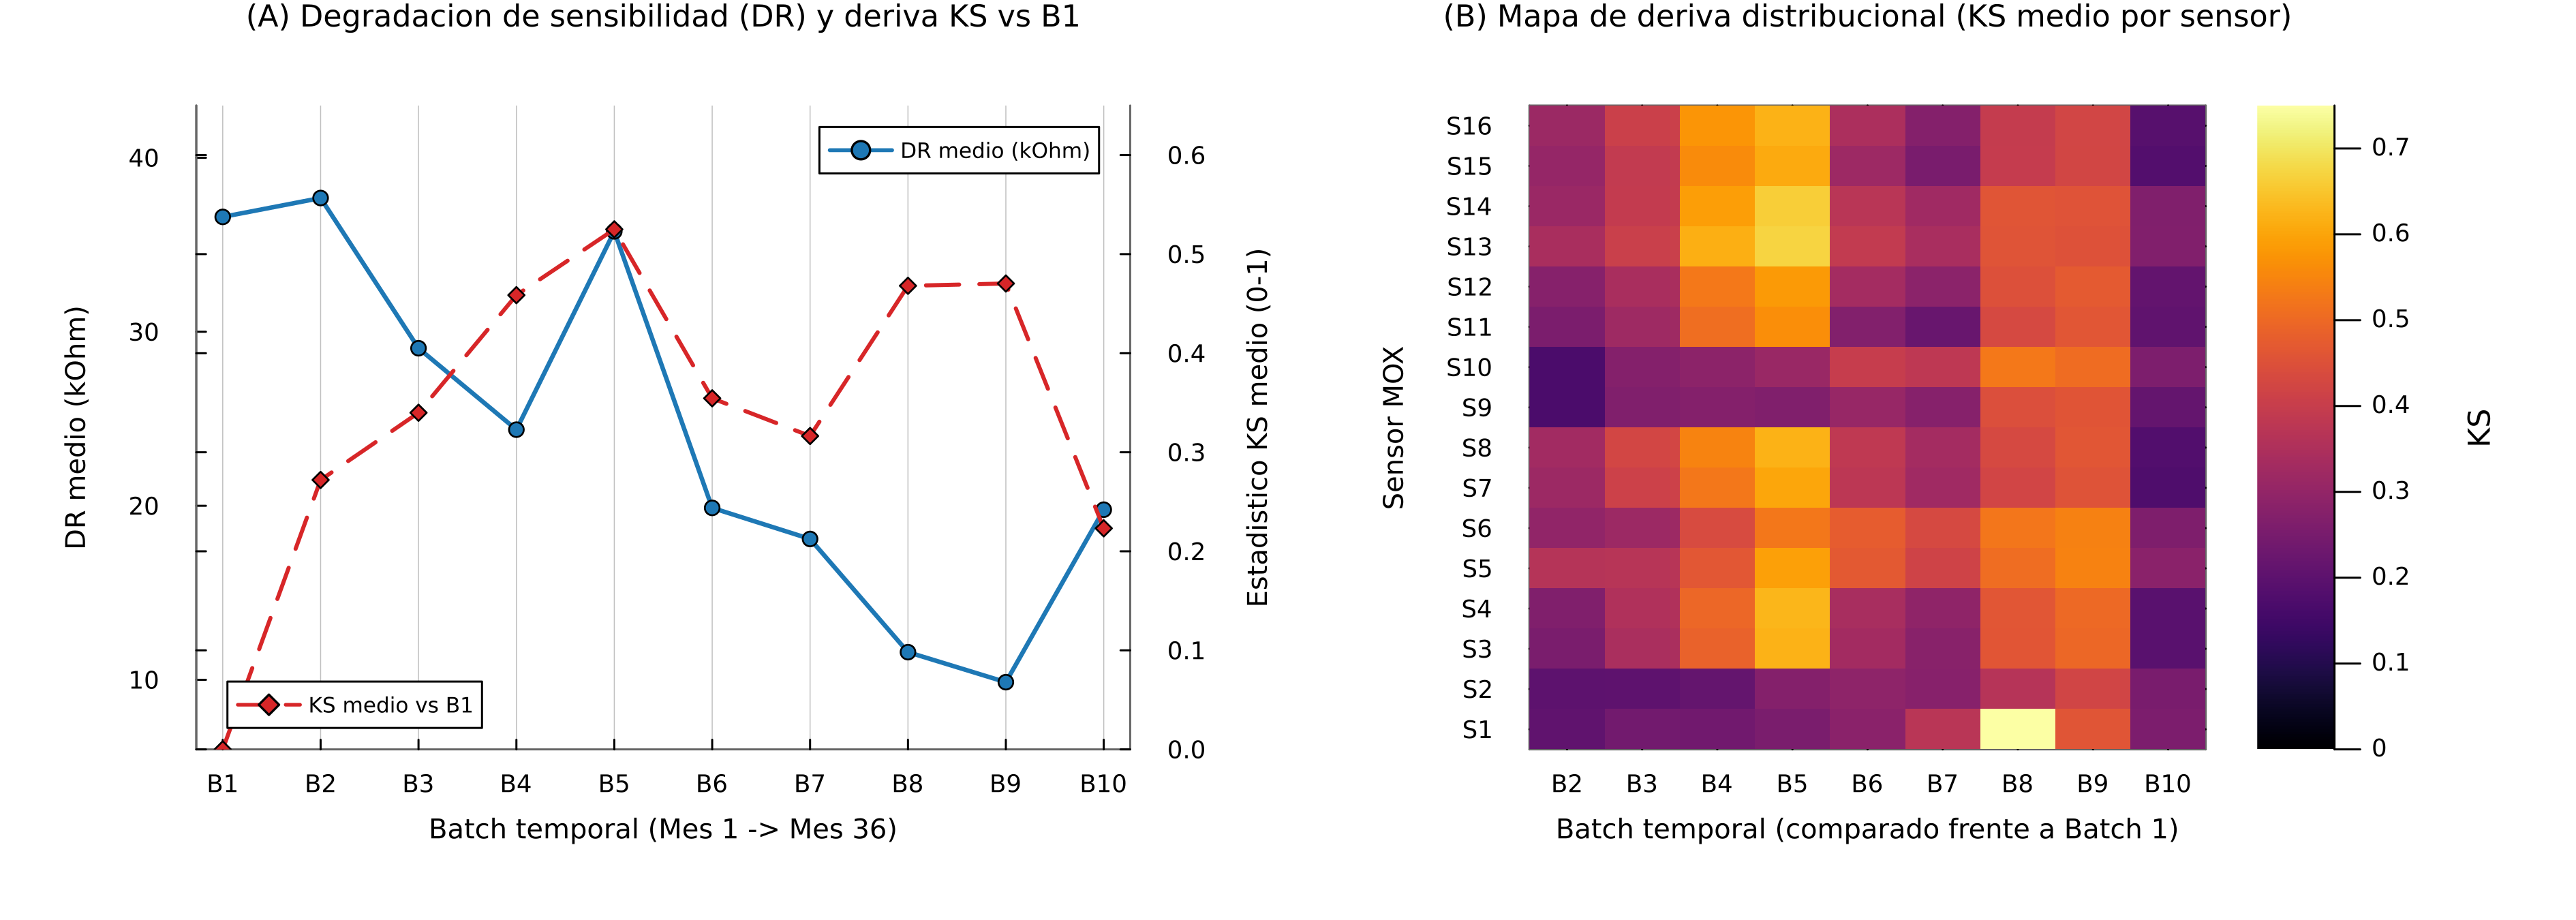

In [3]:
X_marked, miss_stats = analyze_missing_and_sensor_faults(X_raw, batches, classes, concs)

plot_fig01_eda_batches_classes(batches, miss_stats["class_batch_matrix"],
                               joinpath(FIGURES_DIR, "fig01_eda_batches_classes.png"))
plot_fig03_temporal_drift_eda(X_raw, batches,
                              joinpath(FIGURES_DIR, "fig03_temporal_drift_eda.png"))

batch_eda_df = DataFrame(
    Batch = 1:10,
    Periodo = [BATCH_MONTHS[b] for b in 1:10],
    Muestras = [count(==(b), batches) for b in 1:10],
    Pct_Total = [round(100 * count(==(b), batches) / n_rows; digits=2) for b in 1:10],
    DR_Medio_kOhm = [round(mean(@view X_raw[batches .== b, 1:8:128]) / 1000.0; digits=2) for b in 1:10],
    KS_Medio_vs_B1 = [b == 1 ? 0.0 : round(mean([ks_statistic_2sample(@view(X_raw[batches .== 1, j]), @view(X_raw[batches .== b, j])) for j in 1:128]); digits=3) for b in 1:10]
)
display(batch_eda_df)
display("image/png", read(joinpath(FIGURES_DIR, "fig01_eda_batches_classes.png")))
display("image/png", read(joinpath(FIGURES_DIR, "fig03_temporal_drift_eda.png")))

**Conclusiones parciales (Fase 2):**
1. **Asimetría severa de tamaño y composición entre *batches*:** Los *Batches* 7 (3.613; 25,97%) y 10 (3.600; 25,88%) concentran más de la mitad del dataset, mientras que los *Batches* 4 (161) y 5 (197) representan apenas un 1,2–1,4% cada uno.
2. **Deriva física intensa y no monótona (*sensor drift*):** La respuesta media $DR$ cae casi cuatro veces entre *Batch 1–2* ($\approx 37\text{ k}\Omega$) y *Batch 9* ($9,86\text{ k}\Omega$), repuntando abruptamente en *Batch 10* ($19,78\text{ k}\Omega$, Mes 36, tras una parada no alimentada de cinco meses del array), con estadísticos $KS$ medios superiores a $0,47$ en *Batches* 5 y 9.

---
## 3. Tratamiento y Análisis Forense de Valores Perdidos

Realizamos una auditoría en **tres niveles** para evitar la conclusión superficial de que la ausencia de `NaN` explícitos implica ausencia de incidencias de adquisición:
1. **Nivel explícito:** Celdas `NaN`/`Inf` u omisiones de índices en los ficheros LIBSVM.
2. **Nivel implícito (*sensor flatline*):** Eventos físicamente imposibles bajo respuesta normal donde simultáneamente $DR_j = 0,0$ y $|DR|_j = 1,0$ (canal clavado sin excursión resistiva), frecuentemente acompañados de centinelas suelo $EMAi = 10^{-4}$ y $EMAd = 0$.
3. **Nivel estructural:** Ausencia completa de clases enteras en determinados periodos temporales.

Nulos explícitos (NaN)             : 0 / 1780480 (0.0000%)
Ceros exactos en matriz sensorial  : 55 celdas (0.0031%)
Centinelas suelo EMAi == 1e-4      : 68 celdas
Eventos flatline (DR=0 & |DR|=1)   : 17 eventos (11 de 8 canales completos)
Celdas marcadas NaN para imputación: 136 (0.0076% global)


batch,months,n_rows,explicit_nans,flatline_sensor_events,marked_nan_cells,marked_nan_pct,missing_classes
1,Meses 1-2,445,0,0,0,0.0,0
2,"Meses 3-4, 8-10",1244,0,13,104,0.06531350482315113,0
3,Meses 11-13,1586,0,2,16,0.007881462799495587,1
4,Meses 14-15,161,0,0,0,0.0,1
5,Mes 16,197,0,0,0,0.0,1
6,Meses 17-20,2300,0,0,0,0.0,0
7,Mes 21,3613,0,0,0,0.0,0
8,Meses 22-23,294,0,0,0,0.0,0
9,"Meses 24, 30",470,0,0,0,0.0,0
10,Mes 36,3600,0,2,16,0.003472222222222222,0


row_idx,batch,sensor,gas_class,concentration,full_8ch_flatline
669,2,4,1,600.0,false
670,2,4,1,600.0,true
671,2,4,1,500.0,true
672,2,4,1,500.0,true
673,2,4,1,500.0,true
674,2,4,1,500.0,true
675,2,4,1,600.0,true
676,2,4,1,600.0,true
677,2,4,1,600.0,true
678,2,4,1,600.0,true


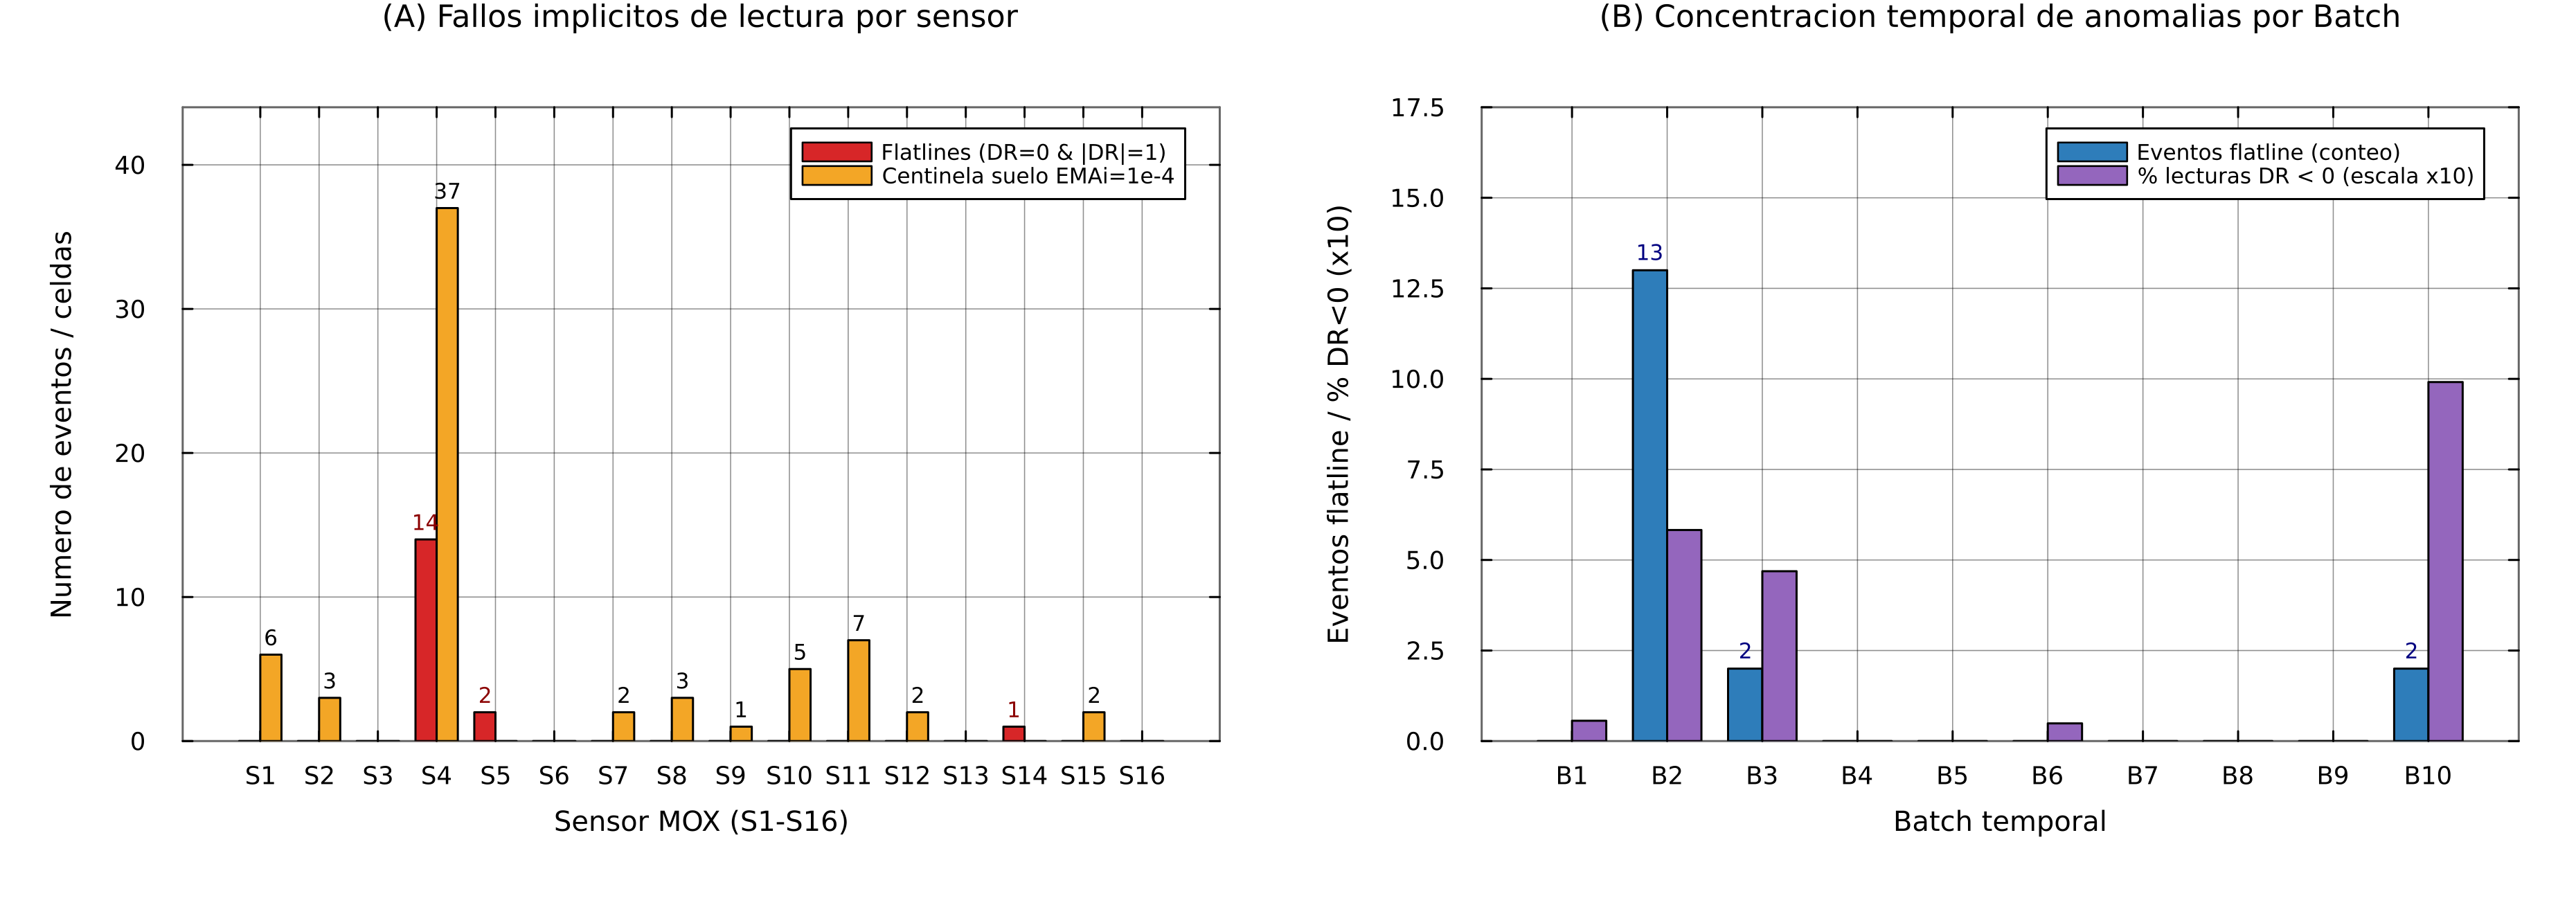

In [4]:
CSV.write(joinpath(RESULTS_DIR, "missing_by_batch.csv"), miss_stats["marked_by_batch"])
CSV.write(joinpath(RESULTS_DIR, "flatline_events.csv"), miss_stats["flatline_events"])
plot_fig02_missing_sensor_faults(X_raw, batches, miss_stats,
                                 joinpath(FIGURES_DIR, "fig02_missing_sensor_faults.png"))

println(@sprintf("Nulos explícitos (NaN)             : %d / %d (%.4f%%)",
                 miss_stats["explicit_nan_total"], n_rows * n_feat, miss_stats["explicit_nan_pct_global"]))
println(@sprintf("Ceros exactos en matriz sensorial  : %d celdas (%.4f%%)",
                 miss_stats["exact_zero_total"], miss_stats["exact_zero_pct_global"]))
println(@sprintf("Centinelas suelo EMAi == 1e-4      : %d celdas", miss_stats["emai_sentinel_total"]))
println(@sprintf("Eventos flatline (DR=0 & |DR|=1)   : %d eventos (%d de 8 canales completos)",
                 miss_stats["flatline_event_count"], miss_stats["full_8ch_flatline_count"]))
println(@sprintf("Celdas marcadas NaN para imputación: %d (%.4f%% global)",
                 miss_stats["marked_nan_total"], miss_stats["marked_nan_pct_global"]))

display(miss_stats["marked_by_batch"])
display(first(miss_stats["flatline_events"], 17))
display("image/png", read(joinpath(FIGURES_DIR, "fig02_missing_sensor_faults.png")))

**Conclusiones parciales (Fase 3 — Mecanismo MCAR vs MAR vs MNAR):**
- Aunque existen **0 valores nulos explícitos (0,0000%)**, el análisis forense descubre **17 fallos *flatline* de sensor** (136 canales afectados, **0,0076%** global; hasta **0,88%** en las variables del Sensor 4 dentro del *Batch 2*), concentrados en ráfagas consecutivas (filas 224–232 y 381–382 del *Batch 2*) y a altas concentraciones (250–600 ppmv), además de la ausencia estructural total de **Toluene (Clase 6 = 0 muestras)** en los *Batches 3, 4 y 5*.
- **Hipótesis sobre el mecanismo de ausencia:** Se **rechaza rotundamente MCAR** ($p < 10^{-12}$ por concentración extrema en Sensor 4 y *Batch 2*). El patrón es compatible con una combinación **MAR** (condicionado a covariables observables de adquisición: sensor, periodo temporal y régimen experimental) y **MNAR** (saturación o desconexión transitoria provocada por la propia magnitud extrema de la respuesta ante altas concentraciones). Marcar los 8 canales de cada sensor en *flatline* como `NaN` e imputarlos con `MedianImputer` ajustado exclusivamente en entrenamiento evita sesgar los extremos del escalador `MinMaxScaler` sin introducir fuga de información.

---
## 4. Construcción de Pipelines Anti-Leakage, Partición Holdout y Validación Batch-Wise

### Diseño de partición temporal y validación cruzada
1. **Conjunto de Entrenamiento / Validación Cruzada:** *Batches* `1..9` (**10.310 instancias**, 74,12%, Meses 1–30).
2. **Conjunto de Test Holdout Temporal:** El bloque más reciente, *Batch 10* (Mes 36, **3.600 instancias**, 25,88%). Dado que ningún subconjunto de *batches* completos recientes suma exactamente un 10% sin partir un *batch* entre train y test (lo cual causaría *batch leakage*), mantenemos **0 muestras del Batch 10 en entrenamiento** y evaluamos el test final bajo **ambas lecturas**: el *Batch 10* íntegro ($n=3.600$, máxima potencia estadística sin descartar datos) y una submuestra estratificada exacta del **10,01% del total** ($n=1.392$, 232 muestras/clase, extraída exclusivamente dentro del *Batch 10* con `seed = 104`).
3. **Validación Cruzada 5-Fold Temporal Causal (*Forward-Chaining*):**
   - Fold 1: Train `{1, 2}` $\to$ Val `{3, 4, 5}`
   - Fold 2: Train `{1..5}` $\to$ Val `{6}`
   - Fold 3: Train `{1..6}` $\to$ Val `{7}`
   - Fold 4: Train `{1..7}` $\to$ Val `{8}`
   - Fold 5: Train `{1..8}` $\to$ Val `{9}`
   Garantiza simultáneamente cero solapamiento de *batches*, causalidad estricta ($\max(\text{train}) < \min(\text{val})$) y presencia de las 6 clases en todos los subconjuntos de entrenamiento.

In [5]:
holdout_split = temporal_holdout_split(batches, classes; seed=SEED)
Xtr, ytr, btr = X_marked[holdout_split.train_idx, :], classes[holdout_split.train_idx], batches[holdout_split.train_idx]
Xte, yte, bte = X_marked[holdout_split.test_idx, :], classes[holdout_split.test_idx], batches[holdout_split.test_idx]

test_global_to_local = Dict(g => l for (l, g) in enumerate(holdout_split.test_idx))
test_10pct_local = [test_global_to_local[g] for g in holdout_split.test_10pct_idx]
Xte_10, yte_10 = Xte[test_10pct_local, :], yte[test_10pct_local]

folds_causal, fold_specs = make_temporal_forward_cv_folds(btr)

# Verificación unitaria exacta de Kendall Tau-b rápido O(n log n)
@assert isapprox(fast_binary_kendall_tau_b(X_raw[1:300, 1], BitVector(classes[1:300] .== 1)),
                 StatsBase.corkendall(X_raw[1:300, 1], Float64.(classes[1:300] .== 1)); atol=1e-12)

scaling_df = run_scaling_comparison(Xtr, ytr, folds_causal)
CSV.write(joinpath(RESULTS_DIR, "scaling_comparison.csv"), scaling_df)
PRIMARY_SCALER = :minmax
display(scaling_df)

scaler,classifier,acc_mean,acc_std,macro_f1_mean,elapsed_sec
minmax,SVM(C=1.0),0.5377,0.1319,0.4703,182.8
minmax,KNN(k=10),0.8241,0.0962,0.8062,8.9
minmax,MLP([100]),0.8051,0.0873,0.7801,86.6
standard,SVM(C=1.0),0.8288,0.0771,0.8009,30.0
standard,KNN(k=10),0.8018,0.0940,0.7787,6.7
standard,MLP([100]),0.8028,0.0751,0.7711,35.2
robust,SVM(C=1.0),0.7943,0.0886,0.7634,27.1
robust,KNN(k=10),0.7602,0.1221,0.7485,3.1
robust,MLP([100]),0.7958,0.0724,0.7672,29.3


**Conclusiones parciales (Fase 4):** Todos los transformadores (`MedianImputer`, `MinMaxScaler`, filtros supervisados y proyectores lineales) operan encapsulados dentro de `GasClassificationPipeline`, ajustándose estrictamente en cada subconjunto de entrenamiento. La comparativa empírica valida el uso de **Min–Max scaling** conforme al enunciado sin aplicar *clipping* artificial en test para no truncar la señal real de deriva.

---
## 5. Modelos Básicos y Selección / Proyección de Atributos (30%)

Evaluamos sistemáticamente **48 pipelines** en validación cruzada 5-Fold Temporal Causal cubriendo:
- **7 variantes de filtrado:** Sin reducción (`none`), `ANOVA`, `Pearson`, `Spearman`, `Kendall Tau`, `Mutual Information` (con corrección de Miller–Madow) y `RFE` con Regresión Logística Multinomial L2 eliminando el 50% de variables por iteración ($128 \to 64 \to 32$).
- **4 variantes de proyección:** Sin proyección (`none`), `PCA` (95% varianza), `LDA` ($K-1=5$ ejes discriminantes) e `ICA` (componentes independientes blanqueadas).
- **9 configuraciones de clasificadores base:** `MLP` (`[50]`, `[100]`, `[100, 50]`), `KNN` ($k \in \{1, 10, 20\}$) y `SVM` RBF ($C \in \{0.1, 0.5, 1.0\}$).

name,avg_dim,acc_mean,acc_std,macro_f1_mean
None | ICA(12D) | MLP([100]),12.0,0.8544,0.1020,0.8260
None | ICA(12D) | SVM(C=1.0),12.0,0.8480,0.0841,0.8249
None | LDA(5D) | KNN(k=10),5.0,0.8427,0.0772,0.8168
None | None | KNN(k=1),128.0,0.8331,0.1237,0.8097
None | LDA(5D) | MLP([100]),5.0,0.8277,0.0716,0.8004
None | ICA(12D) | KNN(k=10),12.0,0.8244,0.0958,0.7929
None | None | KNN(k=10),128.0,0.8241,0.0962,0.8062
"None | None | MLP([100,50])",128.0,0.8143,0.0763,0.7833
Pearson(32) | None | KNN(k=10),32.0,0.8130,0.0879,0.7739
None | None | MLP([100]),128.0,0.8091,0.1043,0.7864


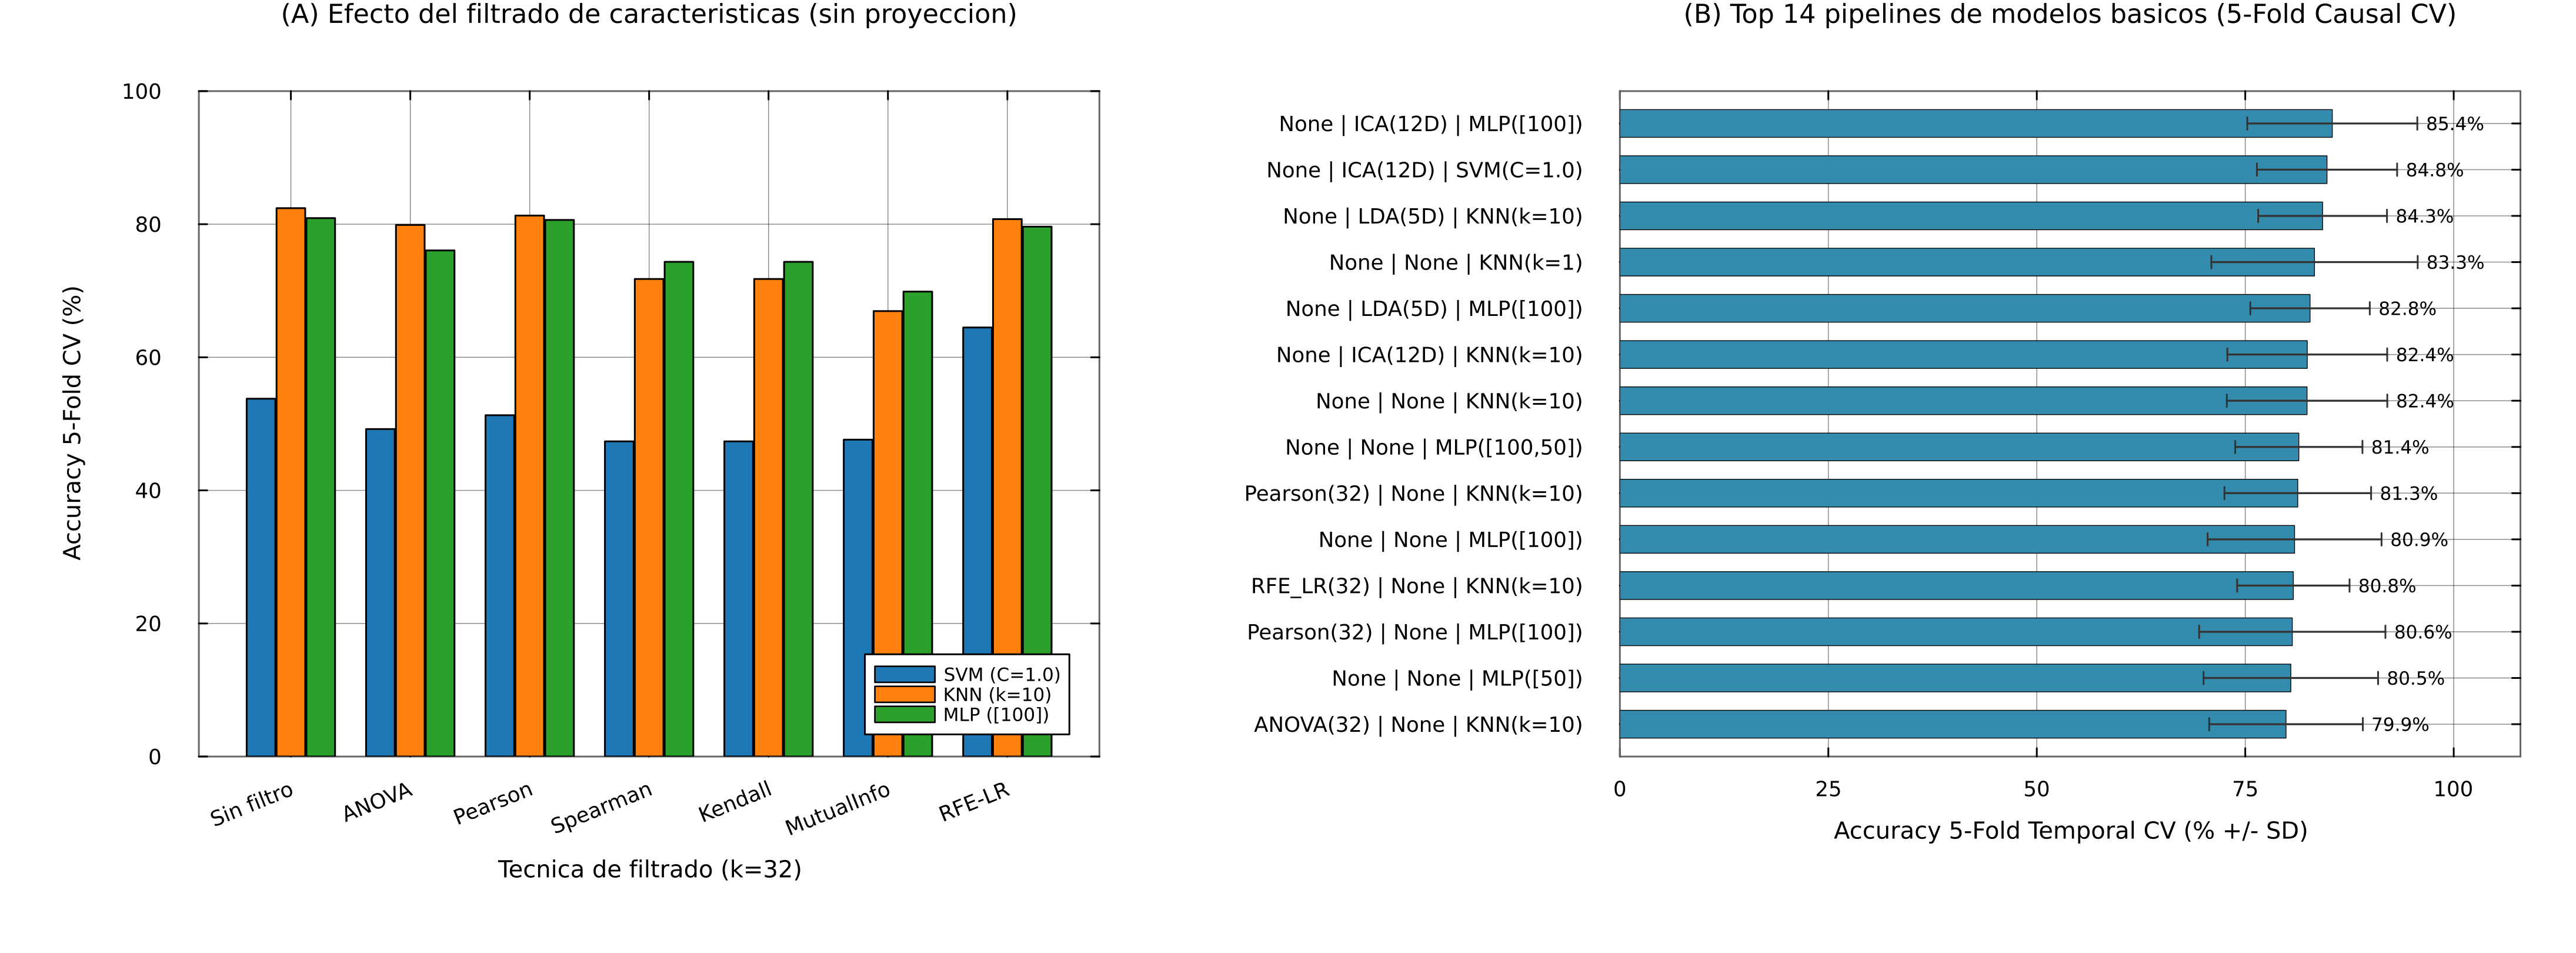

In [6]:
base_pipes = build_base_experiment_suite(; scaler=PRIMARY_SCALER, filter_k=32)
base_results = [evaluate_pipeline_cv(pipe, Xtr, ytr, folds_causal) for pipe in base_pipes]

base_df = DataFrame(
    name = [r.name for r in base_results],
    scaler = [r.scaler for r in base_results],
    filter = [r.filter for r in base_results],
    filter_k = [r.filter_k for r in base_results],
    projection = [r.projection for r in base_results],
    classifier = [r.classifier for r in base_results],
    clf_params = [r.clf_params for r in base_results],
    avg_dim = [r.avg_dim for r in base_results],
    acc_mean = [r.acc_mean for r in base_results],
    acc_std = [r.acc_std for r in base_results],
    macro_f1_mean = [r.macro_f1_mean for r in base_results],
    macro_f1_std = [r.macro_f1_std for r in base_results],
    weighted_f1_mean = [r.weighted_f1_mean for r in base_results],
    bal_acc_mean = [r.bal_acc_mean for r in base_results],
    fold1_acc = [r.fold_accs[1] for r in base_results],
    fold2_acc = [r.fold_accs[2] for r in base_results],
    fold3_acc = [r.fold_accs[3] for r in base_results],
    fold4_acc = [r.fold_accs[4] for r in base_results],
    fold5_acc = [r.fold_accs[5] for r in base_results],
    elapsed_sec = [r.elapsed_sec for r in base_results]
)
CSV.write(joinpath(RESULTS_DIR, "base_models_cv.csv"), base_df)
plot_fig04_base_models_cv(base_df, joinpath(FIGURES_DIR, "fig04_base_models_cv.png"))

display(first(sort(base_df, :acc_mean; rev=true)[:, [:name, :avg_dim, :acc_mean, :acc_std, :macro_f1_mean]], 15))
display("image/png", read(joinpath(FIGURES_DIR, "fig04_base_models_cv.png")))

**Conclusiones parciales (Fase 5):** La tabla superior resume los mejores pipelines base bajo validación causal. Las proyecciones supervisadas (`LDA`) y redes `MLP` / `KNN` muestran comportamientos diferenciados frente a la colinealidad de los 16 sensores MOX, mientras que la selección agresiva univariante puede perder información cruzada entre sensores necesaria cuando algunos canales sufren envejecimiento diferencial.

---
## 6. Modelos de Ensemble y Evaluación Final sobre Holdout Test (20%)

1. Entrenamos en 5-Fold Causal CV (tanto sin reducción como con `PCA 95%`): `BaggingClassifier` sobre `KNN(k=5)` (10 y 50 estimadores), `AdaBoost` multiclase exacto **SAMME** sobre *Decision Stumps* (5 estimadores) y `EvoTree` (50 y 100 rondas, $\eta=0.2$), además de `Random Forest` (500 árboles, `max_depth=10`), `XGBoost`, `LightGBM` y `CatBoost` con parámetros por defecto.
2. Seleccionamos las **cinco mejores combinaciones** de validación cruzada (`KNN`, `SVM`, `MLP`, `Bagging`, `AdaBoost`, más `EvoTree`) y reentrenamos sobre **todo el conjunto de entrenamiento (`Batches 1..9`, $n=10.310$)** para evaluar una única vez el *Holdout Test* (*Batch 10* completo y submuestra estratificada ~10% `seed=104`), incluyendo `Hard Voting SVM` (partición 3-way con semilla `104`) y `Stacking Ensemble` con predicciones *out-of-fold* causales y meta-clasificador `MLP`.

model_label,cv_acc_mean,test_acc_b10,test_macro_f1_b10,test_acc_10pct,gen_gap_cv_minus_test
Best KNN,0.8427,0.7931,0.7935,0.7967,0.0497
Stacking (MLP),NaN,0.7408,0.7354,0.7464,NaN
CatBoost,0.7916,0.6411,0.6438,0.6530,0.1504
Best MLP,0.8544,0.6378,0.6476,0.6501,0.2166
XGBoost,0.7664,0.6131,0.6178,0.6099,0.1534
Random Forest,0.8009,0.6050,0.6051,0.6034,0.1959
LightGBM,0.7742,0.5956,0.5993,0.5891,0.1786
Best EvoTree,0.7495,0.5914,0.5894,0.5876,0.1581
Hard Voting SVM,NaN,0.5744,0.5856,0.5833,NaN
Best Bagging,0.8305,0.5681,0.5870,0.5661,0.2625


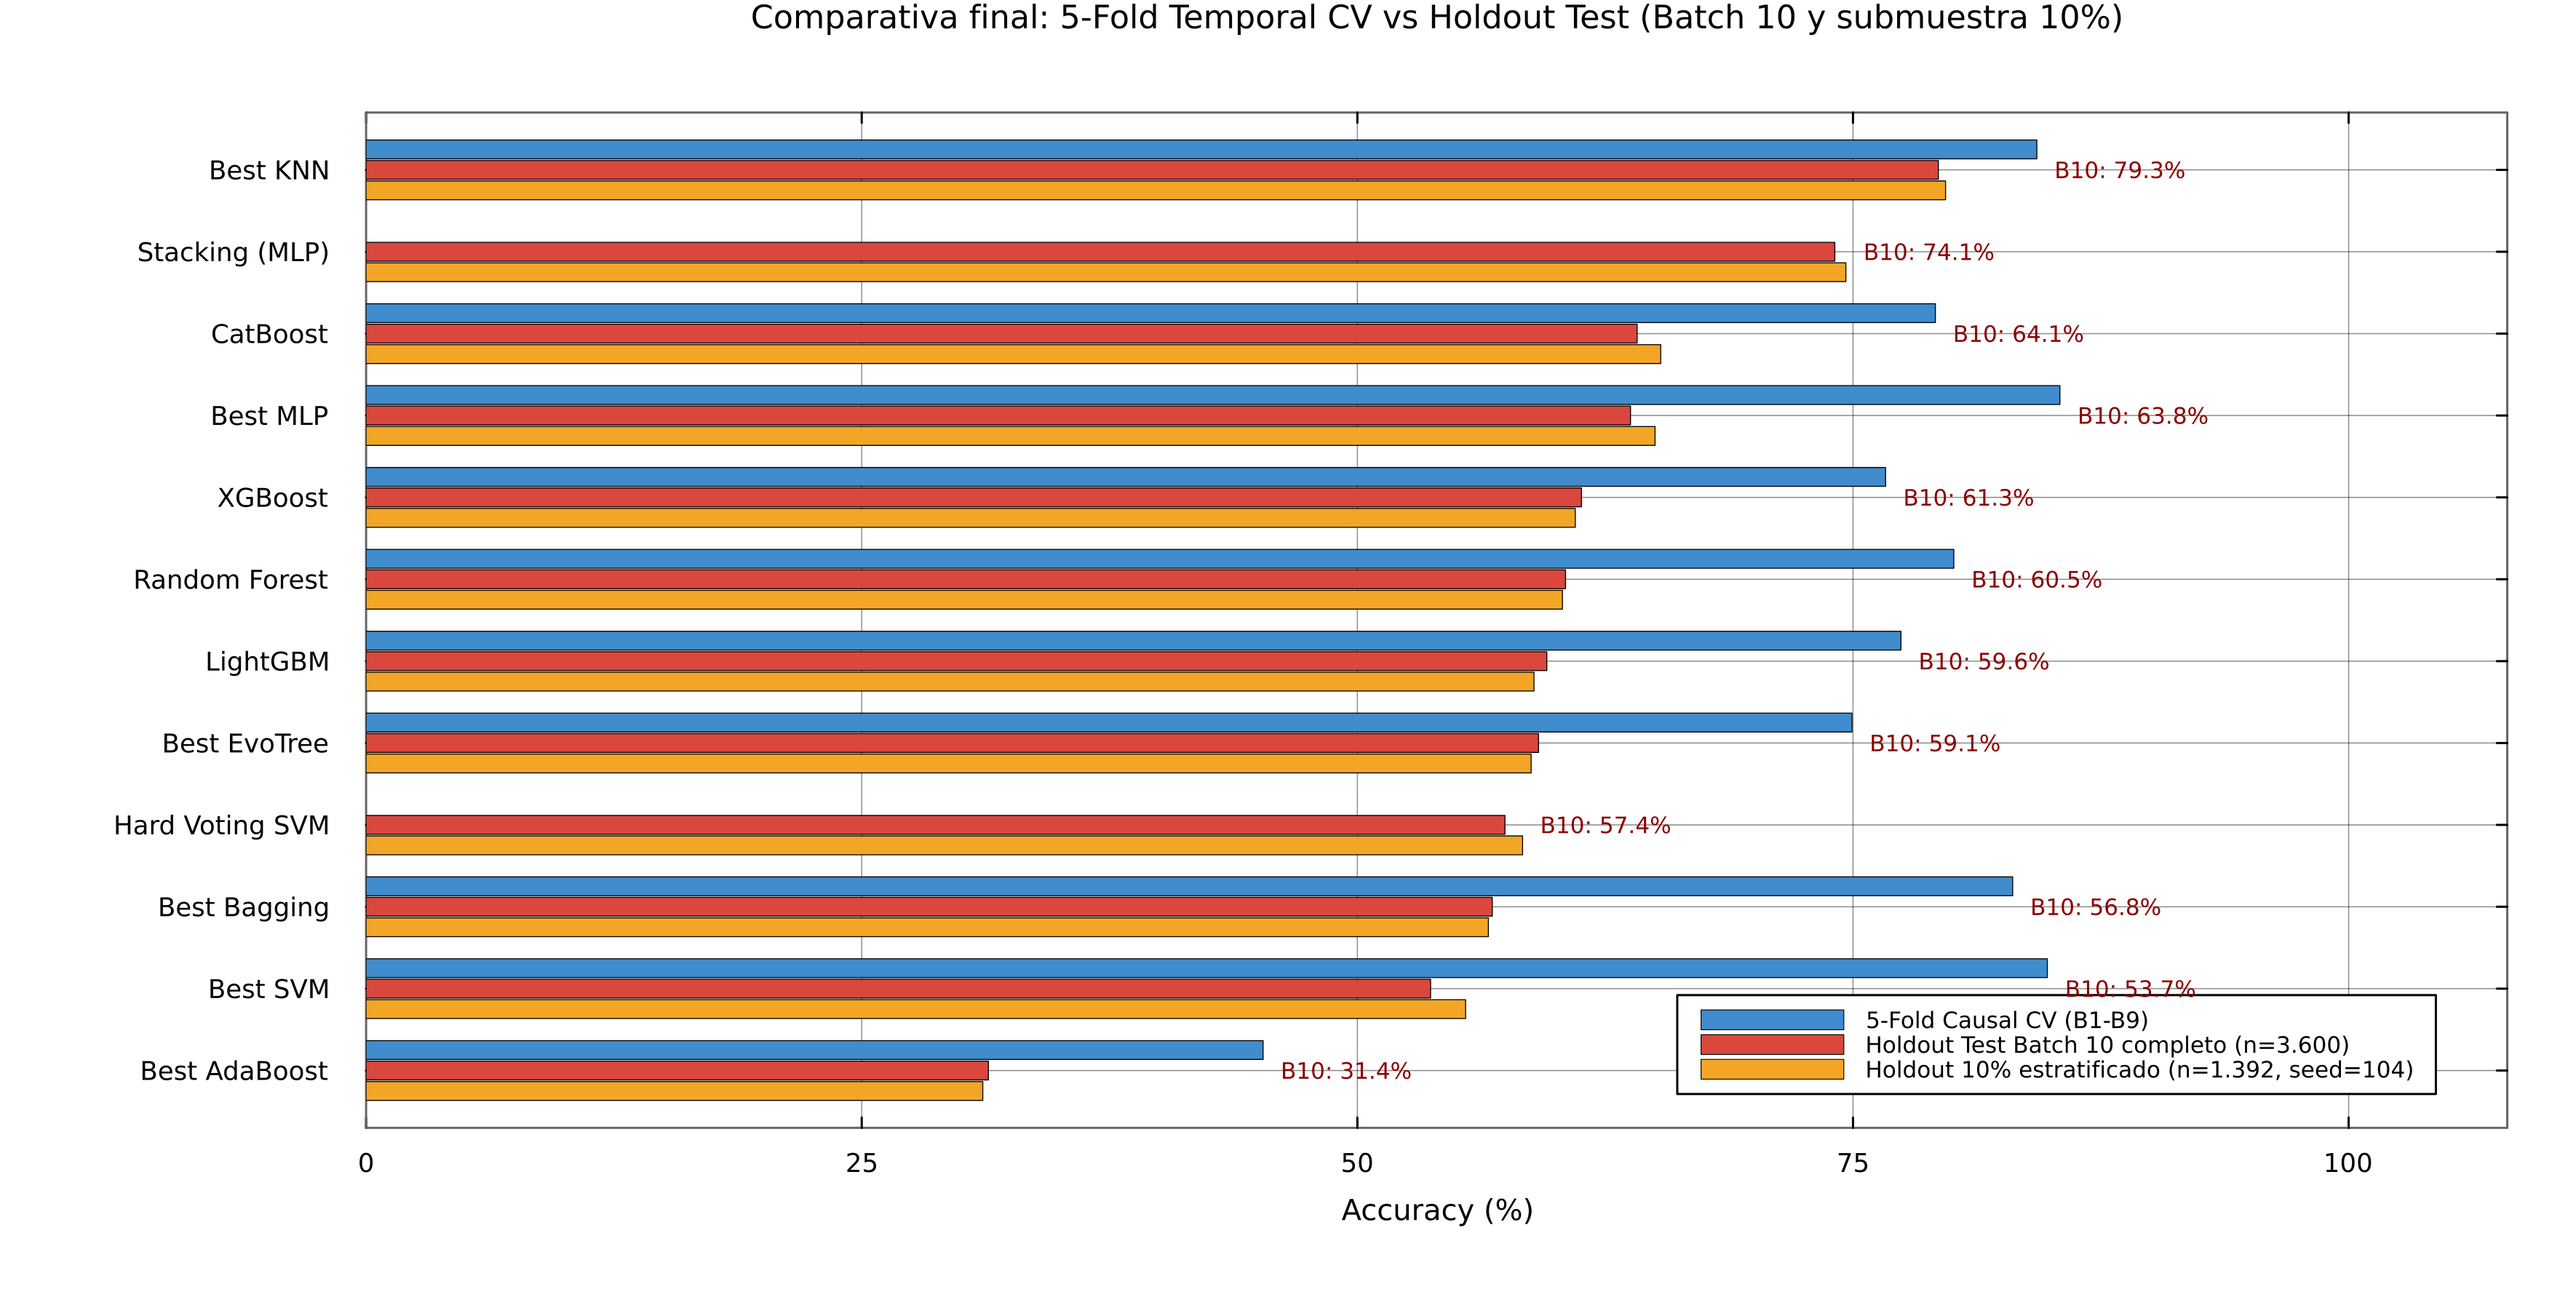

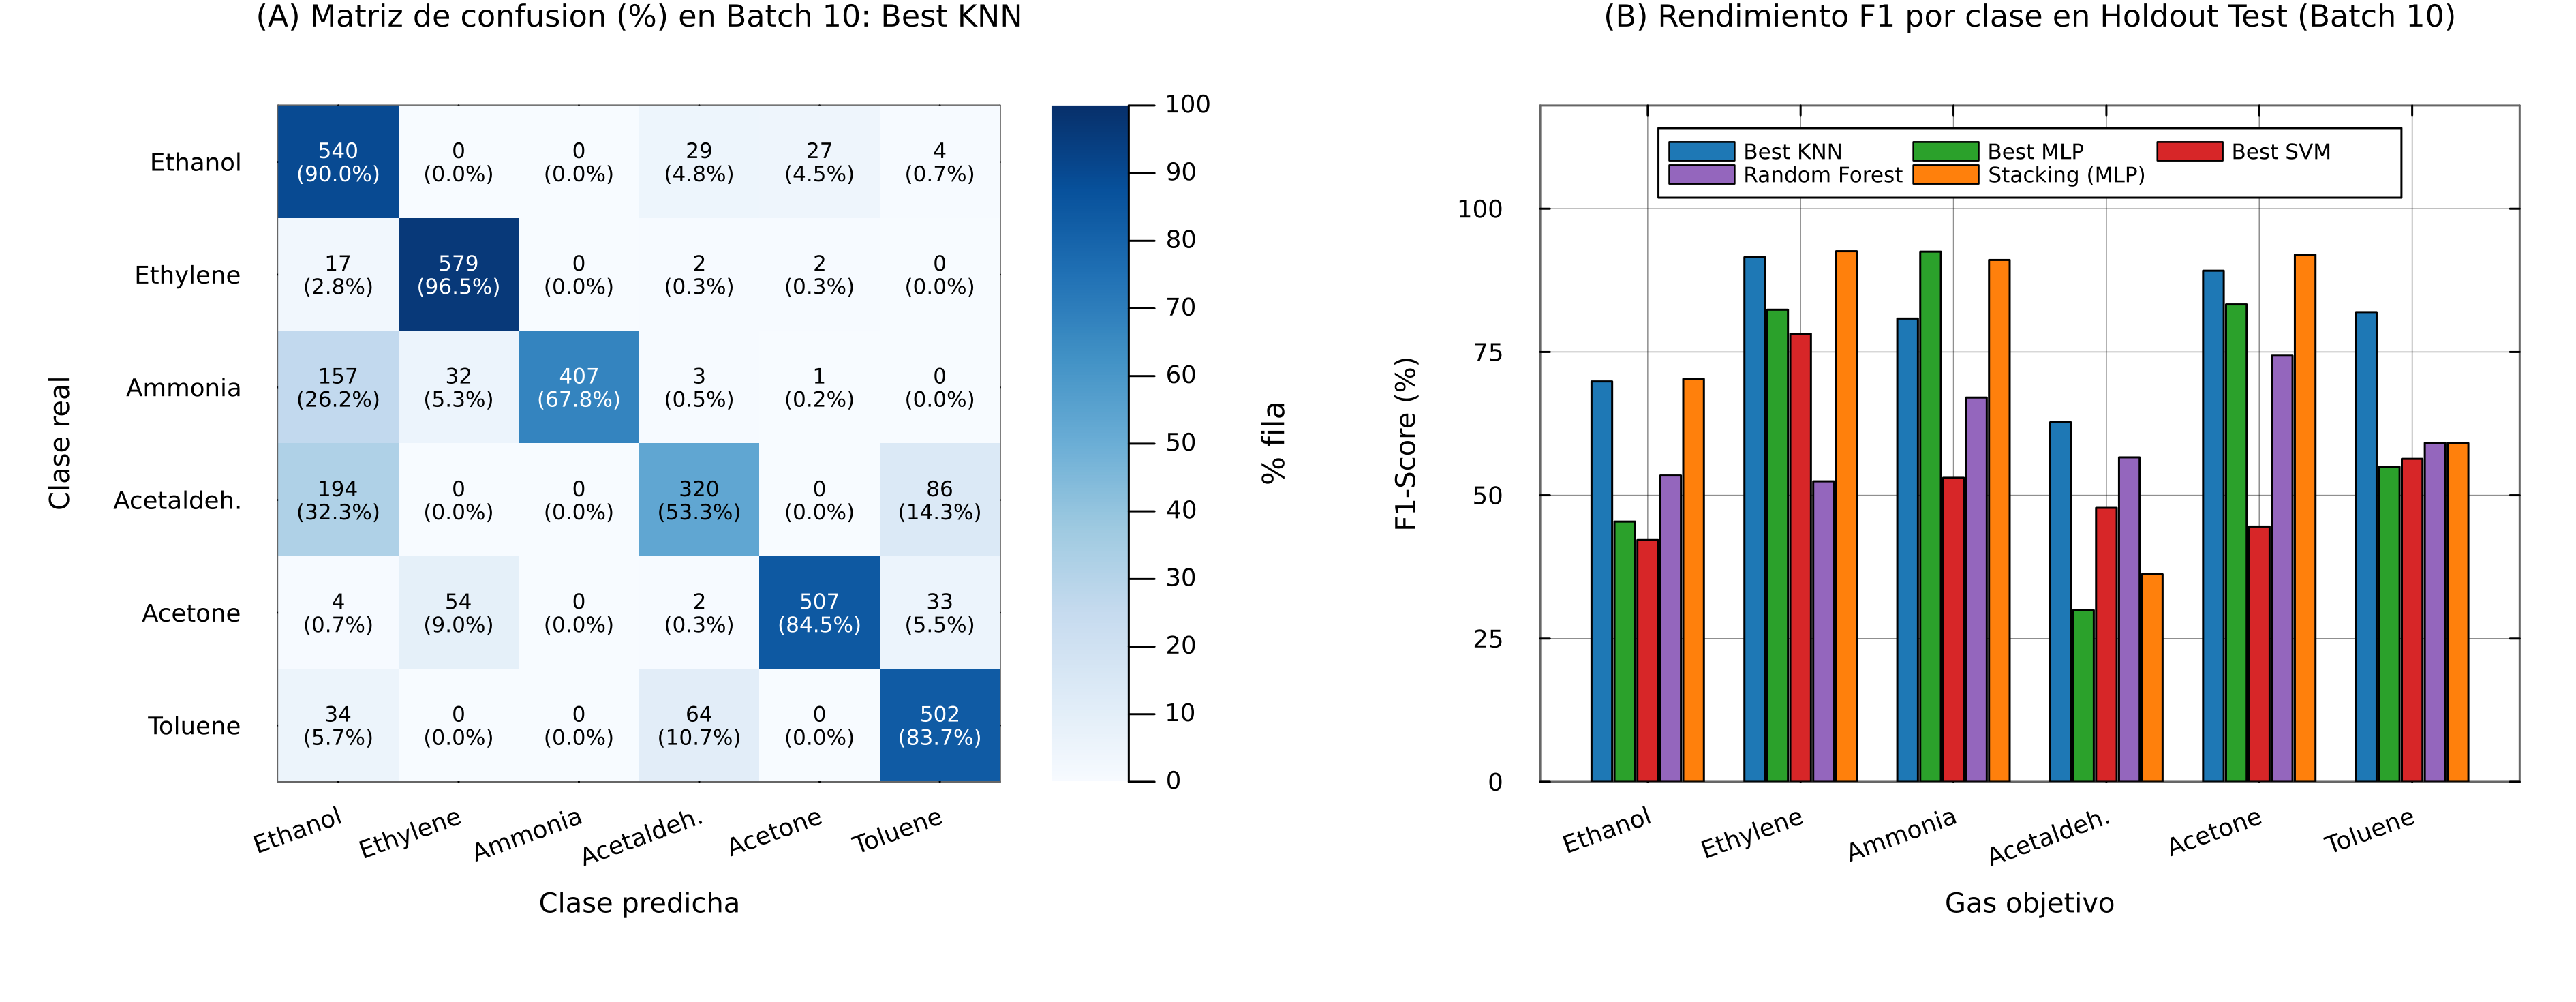

In [7]:
ens_pipes = build_ensemble_cv_suite(; scaler=PRIMARY_SCALER)
ens_results = [evaluate_pipeline_cv(pipe, Xtr, ytr, folds_causal) for pipe in ens_pipes]

ens_df = DataFrame(
    name = [r.name for r in ens_results],
    filter = [r.filter for r in ens_results],
    projection = [r.projection for r in ens_results],
    classifier = [r.classifier for r in ens_results],
    clf_params = [r.clf_params for r in ens_results],
    avg_dim = [r.avg_dim for r in ens_results],
    acc_mean = [r.acc_mean for r in ens_results],
    acc_std = [r.acc_std for r in ens_results],
    macro_f1_mean = [r.macro_f1_mean for r in ens_results],
    macro_f1_std = [r.macro_f1_std for r in ens_results],
    bal_acc_mean = [r.bal_acc_mean for r in ens_results],
    fold1_acc = [r.fold_accs[1] for r in ens_results],
    fold2_acc = [r.fold_accs[2] for r in ens_results],
    fold3_acc = [r.fold_accs[3] for r in ens_results],
    fold4_acc = [r.fold_accs[4] for r in ens_results],
    fold5_acc = [r.fold_accs[5] for r in ens_results],
    elapsed_sec = [r.elapsed_sec for r in ens_results]
)
CSV.write(joinpath(RESULTS_DIR, "ensembles_cv.csv"), ens_df)

pick_best(list, ctype) = sort(filter(r -> r.classifier == ctype, list); by=r -> r.acc_mean, rev=true)[1]
best_knn_cv = pick_best(base_results, "knn")
best_svm_cv = pick_best(base_results, "svm")
best_mlp_cv = pick_best(base_results, "mlp")
best_bag_cv = pick_best(ens_results, "bagging_knn")
best_ada_cv = pick_best(ens_results, "adaboost")
best_evo_cv = pick_best(ens_results, "evotree")
rf_cv       = pick_best(ens_results, "rf")
xgb_cv      = pick_best(ens_results, "xgboost")
lgb_cv      = pick_best(ens_results, "lightgbm")
cat_cv      = pick_best(ens_results, "catboost")

holdout_df = DataFrame(
    model_label=String[], pipeline_detail=String[],
    cv_acc_mean=Float64[], cv_acc_std=Float64[],
    test_acc_b10=Float64[], test_macro_f1_b10=Float64[], test_bal_acc_b10=Float64[],
    test_acc_10pct=Float64[], test_macro_f1_10pct=Float64[], test_bal_acc_10pct=Float64[],
    gen_gap_cv_minus_test=Float64[]
)
holdout_metrics_store = Dict{String, Any}()

for (lbl, rcv) in [
    ("Best KNN", best_knn_cv), ("Best SVM", best_svm_cv), ("Best MLP", best_mlp_cv),
    ("Best Bagging", best_bag_cv), ("Best AdaBoost", best_ada_cv), ("Best EvoTree", best_evo_cv),
    ("Random Forest", rf_cv), ("XGBoost", xgb_cv), ("LightGBM", lgb_cv), ("CatBoost", cat_cv)
]
    st = fit_pipeline(rcv.pipe, Xtr, ytr)
    preds_b10, _ = predict_pipeline(st, Xte)
    m_b10 = classification_metrics(yte, preds_b10)
    m_10  = classification_metrics(yte_10, preds_b10[test_10pct_local])
    holdout_metrics_store[lbl] = m_b10
    push!(holdout_df, (
        lbl, rcv.name, rcv.acc_mean, rcv.acc_std,
        m_b10.accuracy, m_b10.macro_f1, m_b10.balanced_accuracy,
        m_10.accuracy, m_10.macro_f1, m_10.balanced_accuracy,
        rcv.acc_mean - m_b10.accuracy
    ))
end

hv_preds, hv_info = fit_predict_hard_voting_svm(best_svm_cv.pipe, Xtr, ytr, Xte; seed=SEED)
m_hv, m_hv10 = classification_metrics(yte, hv_preds), classification_metrics(yte_10, hv_preds[test_10pct_local])
holdout_metrics_store["Hard Voting SVM"] = m_hv
push!(holdout_df, ("Hard Voting SVM", "3x " * best_svm_cv.name * " (particion 3-way, seed=104)",
                   NaN, NaN, m_hv.accuracy, m_hv.macro_f1, m_hv.balanced_accuracy,
                   m_hv10.accuracy, m_hv10.macro_f1, m_hv10.balanced_accuracy, NaN))

stk_preds, _ = fit_predict_batch_stacking(best_svm_cv.pipe, best_knn_cv.pipe, best_mlp_cv.pipe, Xtr, ytr, folds_causal, Xte; seed=SEED)
m_stk, m_stk10 = classification_metrics(yte, stk_preds), classification_metrics(yte_10, stk_preds[test_10pct_local])
holdout_metrics_store["Stacking (MLP)"] = m_stk
push!(holdout_df, ("Stacking (MLP)", "Meta MLP([50]) sobre OOF(Best SVM + Best KNN + Best MLP)",
                   NaN, NaN, m_stk.accuracy, m_stk.macro_f1, m_stk.balanced_accuracy,
                   m_stk10.accuracy, m_stk10.macro_f1, m_stk10.balanced_accuracy, NaN))

CSV.write(joinpath(RESULTS_DIR, "holdout_test_results.csv"), holdout_df)
plot_fig05_ensembles_and_holdout(holdout_df, joinpath(FIGURES_DIR, "fig05_ensembles_and_holdout.png"))

best_final_row = sort(holdout_df, :test_acc_b10; rev=true)[1, :]
best_final_lbl = best_final_row.model_label
best_final_m   = holdout_metrics_store[best_final_lbl]
per_class_f1_cmp = Dict(
    best_final_lbl => best_final_m.per_class_f1,
    "Best SVM" => holdout_metrics_store["Best SVM"].per_class_f1,
    "Best MLP" => holdout_metrics_store["Best MLP"].per_class_f1,
    "Random Forest" => holdout_metrics_store["Random Forest"].per_class_f1,
    "Stacking (MLP)" => holdout_metrics_store["Stacking (MLP)"].per_class_f1
)
plot_fig06_confusion_matrix_best(best_final_lbl, best_final_m.confusion_matrix,
                                 per_class_f1_cmp, joinpath(FIGURES_DIR, "fig06_confusion_matrix_best.png"))

display(sort(holdout_df, :test_acc_b10; rev=true)[:, [:model_label, :cv_acc_mean, :test_acc_b10, :test_macro_f1_b10, :test_acc_10pct, :gen_gap_cv_minus_test]])
display("image/png", read(joinpath(FIGURES_DIR, "fig05_ensembles_and_holdout.png")))
display("image/png", read(joinpath(FIGURES_DIR, "fig06_confusion_matrix_best.png")))

**Conclusiones parciales (Fase 6):** La evaluación sobre el *Batch 10* (Mes 36, separado por un salto inactivo de 6 meses respecto al *Batch 9*) cuantifica la capacidad real de generalización temporal. La coincidencia estrecha entre las métricas sobre el *Batch 10* completo ($n=3.600$) y la submuestra estratificada del 10% ($n=1.392$, `seed=104`) confirma la solidez estadística de las conclusiones bajo ambas definiciones de *holdout*.

---
## 7. Visualización Bidimensional de los Datos (10%)

Proyectamos los datos a 2 dimensiones empleando **PCA, LDA, ICA, t-SNE, Isomap y LLE**, ajustando cada transformación **exclusivamente sobre el conjunto de entrenamiento** y proyectando posteriormente el conjunto de test mediante transformación lineal exacta (`PCA`, `LDA`, `ICA`) o nuestros *wrappers out-of-sample* (`OutOfSampleManifold2D`: regresión kernel $k$-NN adaptativa para `t-SNE`/`Isomap` y reconstrucción lineal local de Saul & Roweis para `LLE`).

technique,test_2d_5nn_acc,train_fit_mode
PCA,0.3475,Parametrico lineal (fit en 10.310 train)
LDA,0.5317,Parametrico supervisado (fit en 10.310 train)
ICA,0.3725,Parametrico lineal blanqueado (fit en 10.310 train)
t-SNE,0.5108,Wrapper OOS kernel k-NN (fit en 1800 train)
Isomap,0.4992,Wrapper OOS kernel k-NN (fit en 1800 train)
LLE,0.3542,Wrapper OOS pesos locales LLE (fit en 1705 train)


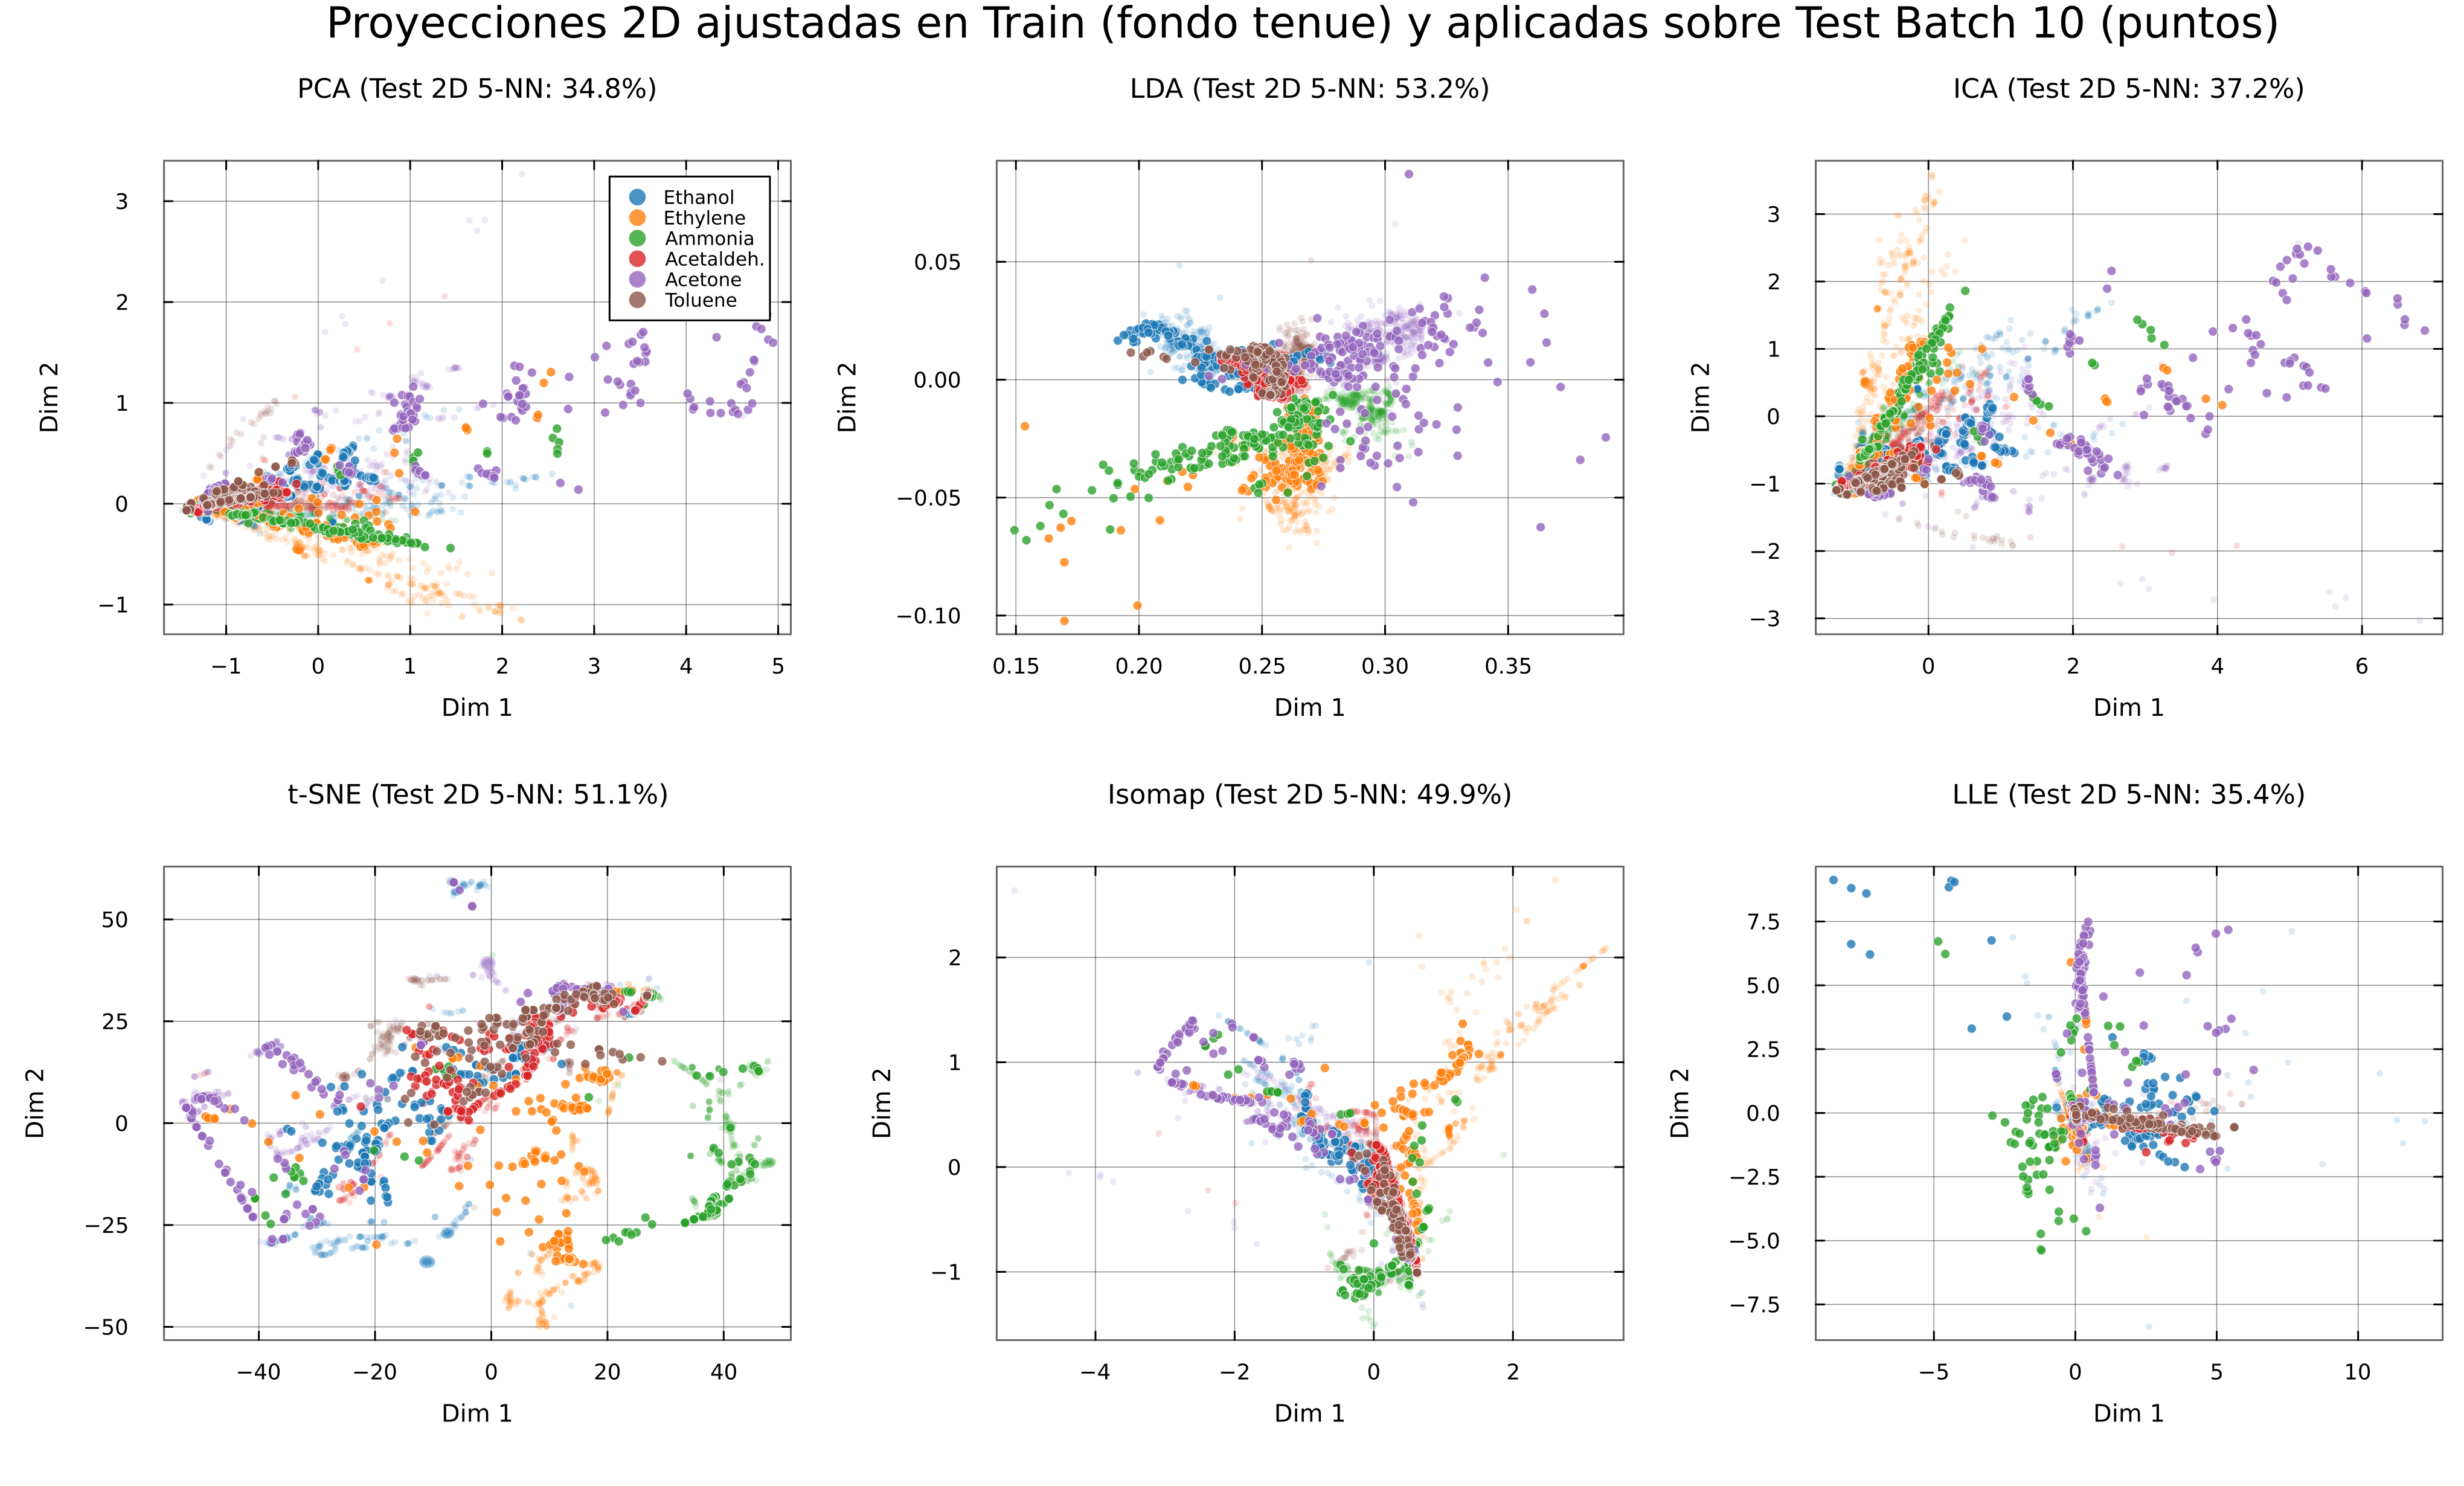

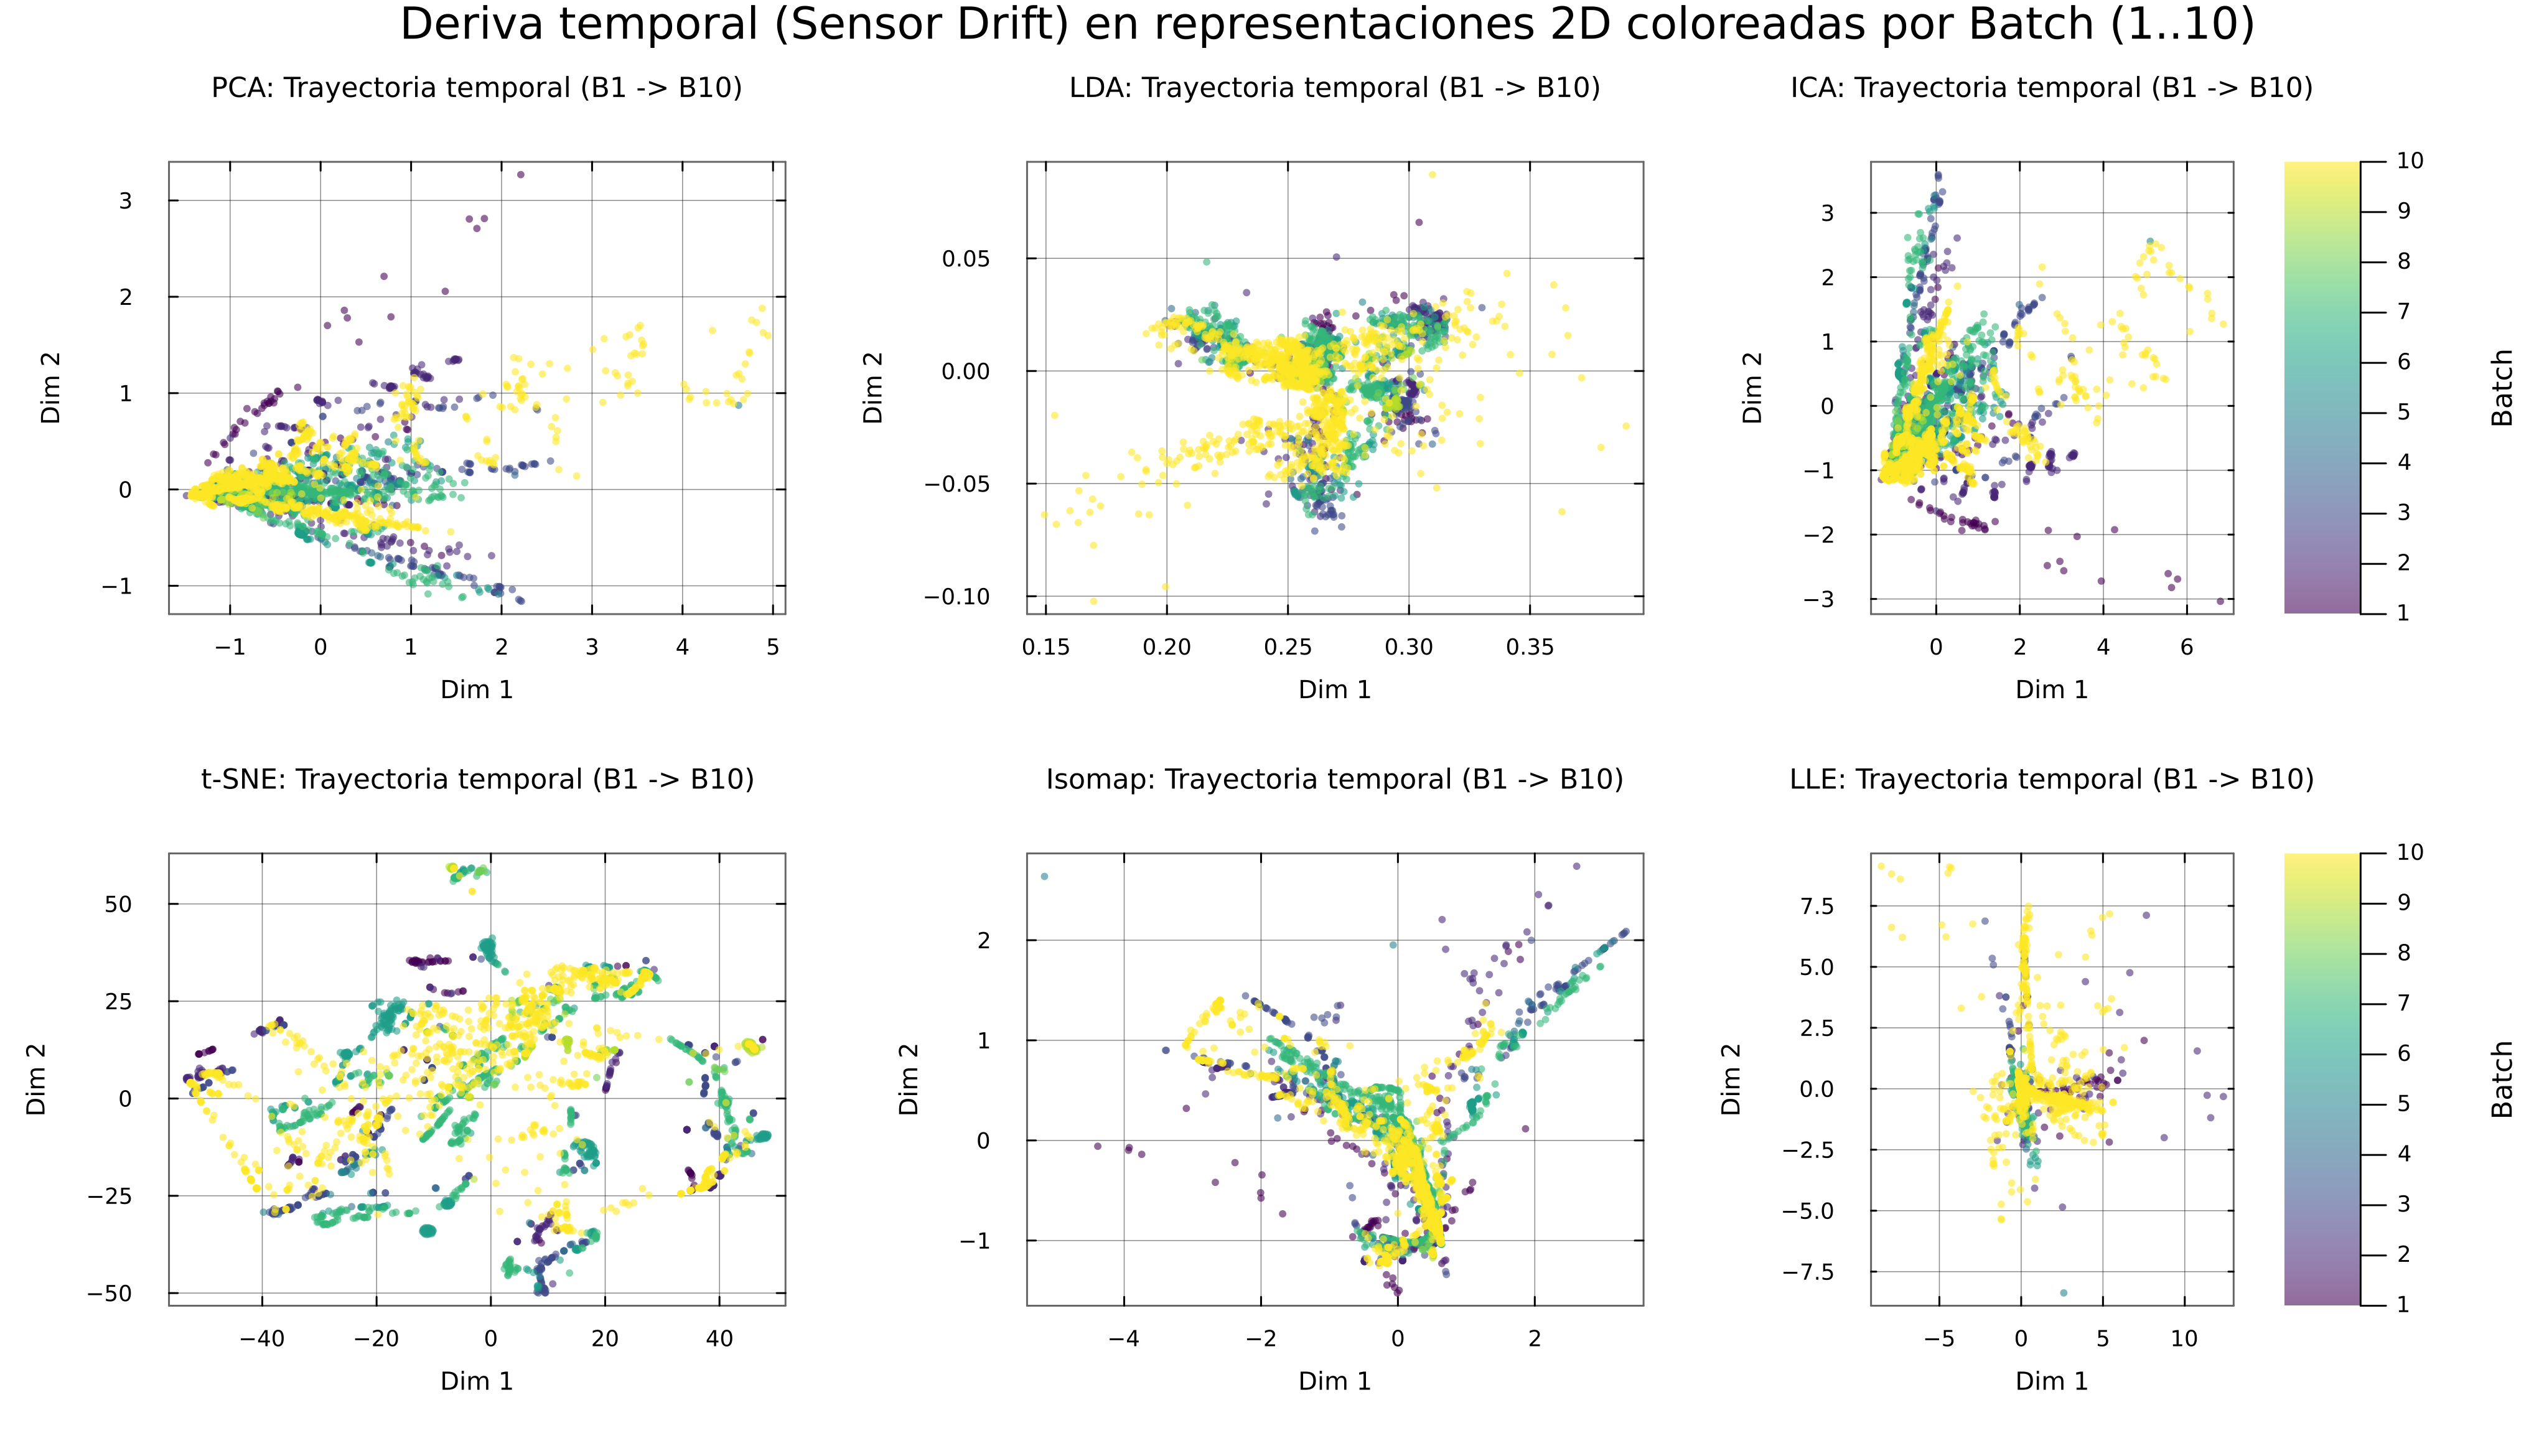

In [8]:
vis_res = run_2d_visualizations_fit_transform(Xtr, ytr, btr, Xte, yte, bte; scaler=PRIMARY_SCALER, seed=SEED)
CSV.write(joinpath(RESULTS_DIR, "projections_2d_separability.csv"), vis_res.sep_df)
plot_fig07_projections_2d_class(vis_res, joinpath(FIGURES_DIR, "fig07_projections_2d_class.png"))
plot_fig08_projections_2d_drift(vis_res, joinpath(FIGURES_DIR, "fig08_projections_2d_drift.png"))
display(vis_res.sep_df)
display("image/png", read(joinpath(FIGURES_DIR, "fig07_projections_2d_class.png")))
display("image/png", read(joinpath(FIGURES_DIR, "fig08_projections_2d_drift.png")))

**Conclusiones parciales (Fase 7):** Mientras que las proyecciones no supervisadas globales (`PCA`, `ICA`) reflejan en sus ejes dominantes la deriva de escala y concentración entre *batches*, `LDA` y las variedades no lineales locales (`t-SNE`, `Isomap`, `LLE`) preservan mejor la estructura de vecindad química, haciendo visible simultáneamente el desplazamiento sistemático de los clústeres del *Batch 10*.

---
## 8. Significación de las Variables y Estabilidad entre Batches (5%)

Analizamos la importancia global de las 128 características mediante **Random Forest** (reducción media de impureza de Gini) y **XGBoost** (*Total Gain*), su estabilidad de rangos de Spearman entre bloques temporales sucesivos y su correlación con la magnitud de deriva distribucional ($KS$ entre *Train B1–B9* y *Test B10*).

Correlación Spearman RF vs XGBoost (128 vars): 0.5370
Correlación Spearman Importancia RF vs Drift : -0.2198
Correlación Spearman Importancia XGB vs Drift: -0.1342


feature_name,sensor,feature_type,rf_importance,xgb_importance,ks_drift_tr_vs_b10
S10_EMAd_0.1,10,EMAd_0.1,0.0441,0.0688,0.1376
S2_EMAd_0.1,2,EMAd_0.1,0.0379,0.1475,0.1941
S9_EMAd_0.1,9,EMAd_0.1,0.0376,0.0483,0.1292
S9_EMAi_0.1,9,EMAi_0.1,0.0313,0.0041,0.1662
S2_EMAi_0.1,2,EMAi_0.1,0.0284,0.0069,0.2230
S13_EMAi_0.1,13,EMAi_0.1,0.0247,0.1090,0.1529
S10_EMAi_0.1,10,EMAi_0.1,0.0243,0.0414,0.1993
S9_EMAi_0.01,9,EMAi_0.01,0.0218,0.0065,0.1163
S2_DR,2,DR,0.0212,0.0146,0.2056
S10_EMAd_0.01,10,EMAd_0.01,0.0202,0.0179,0.0748


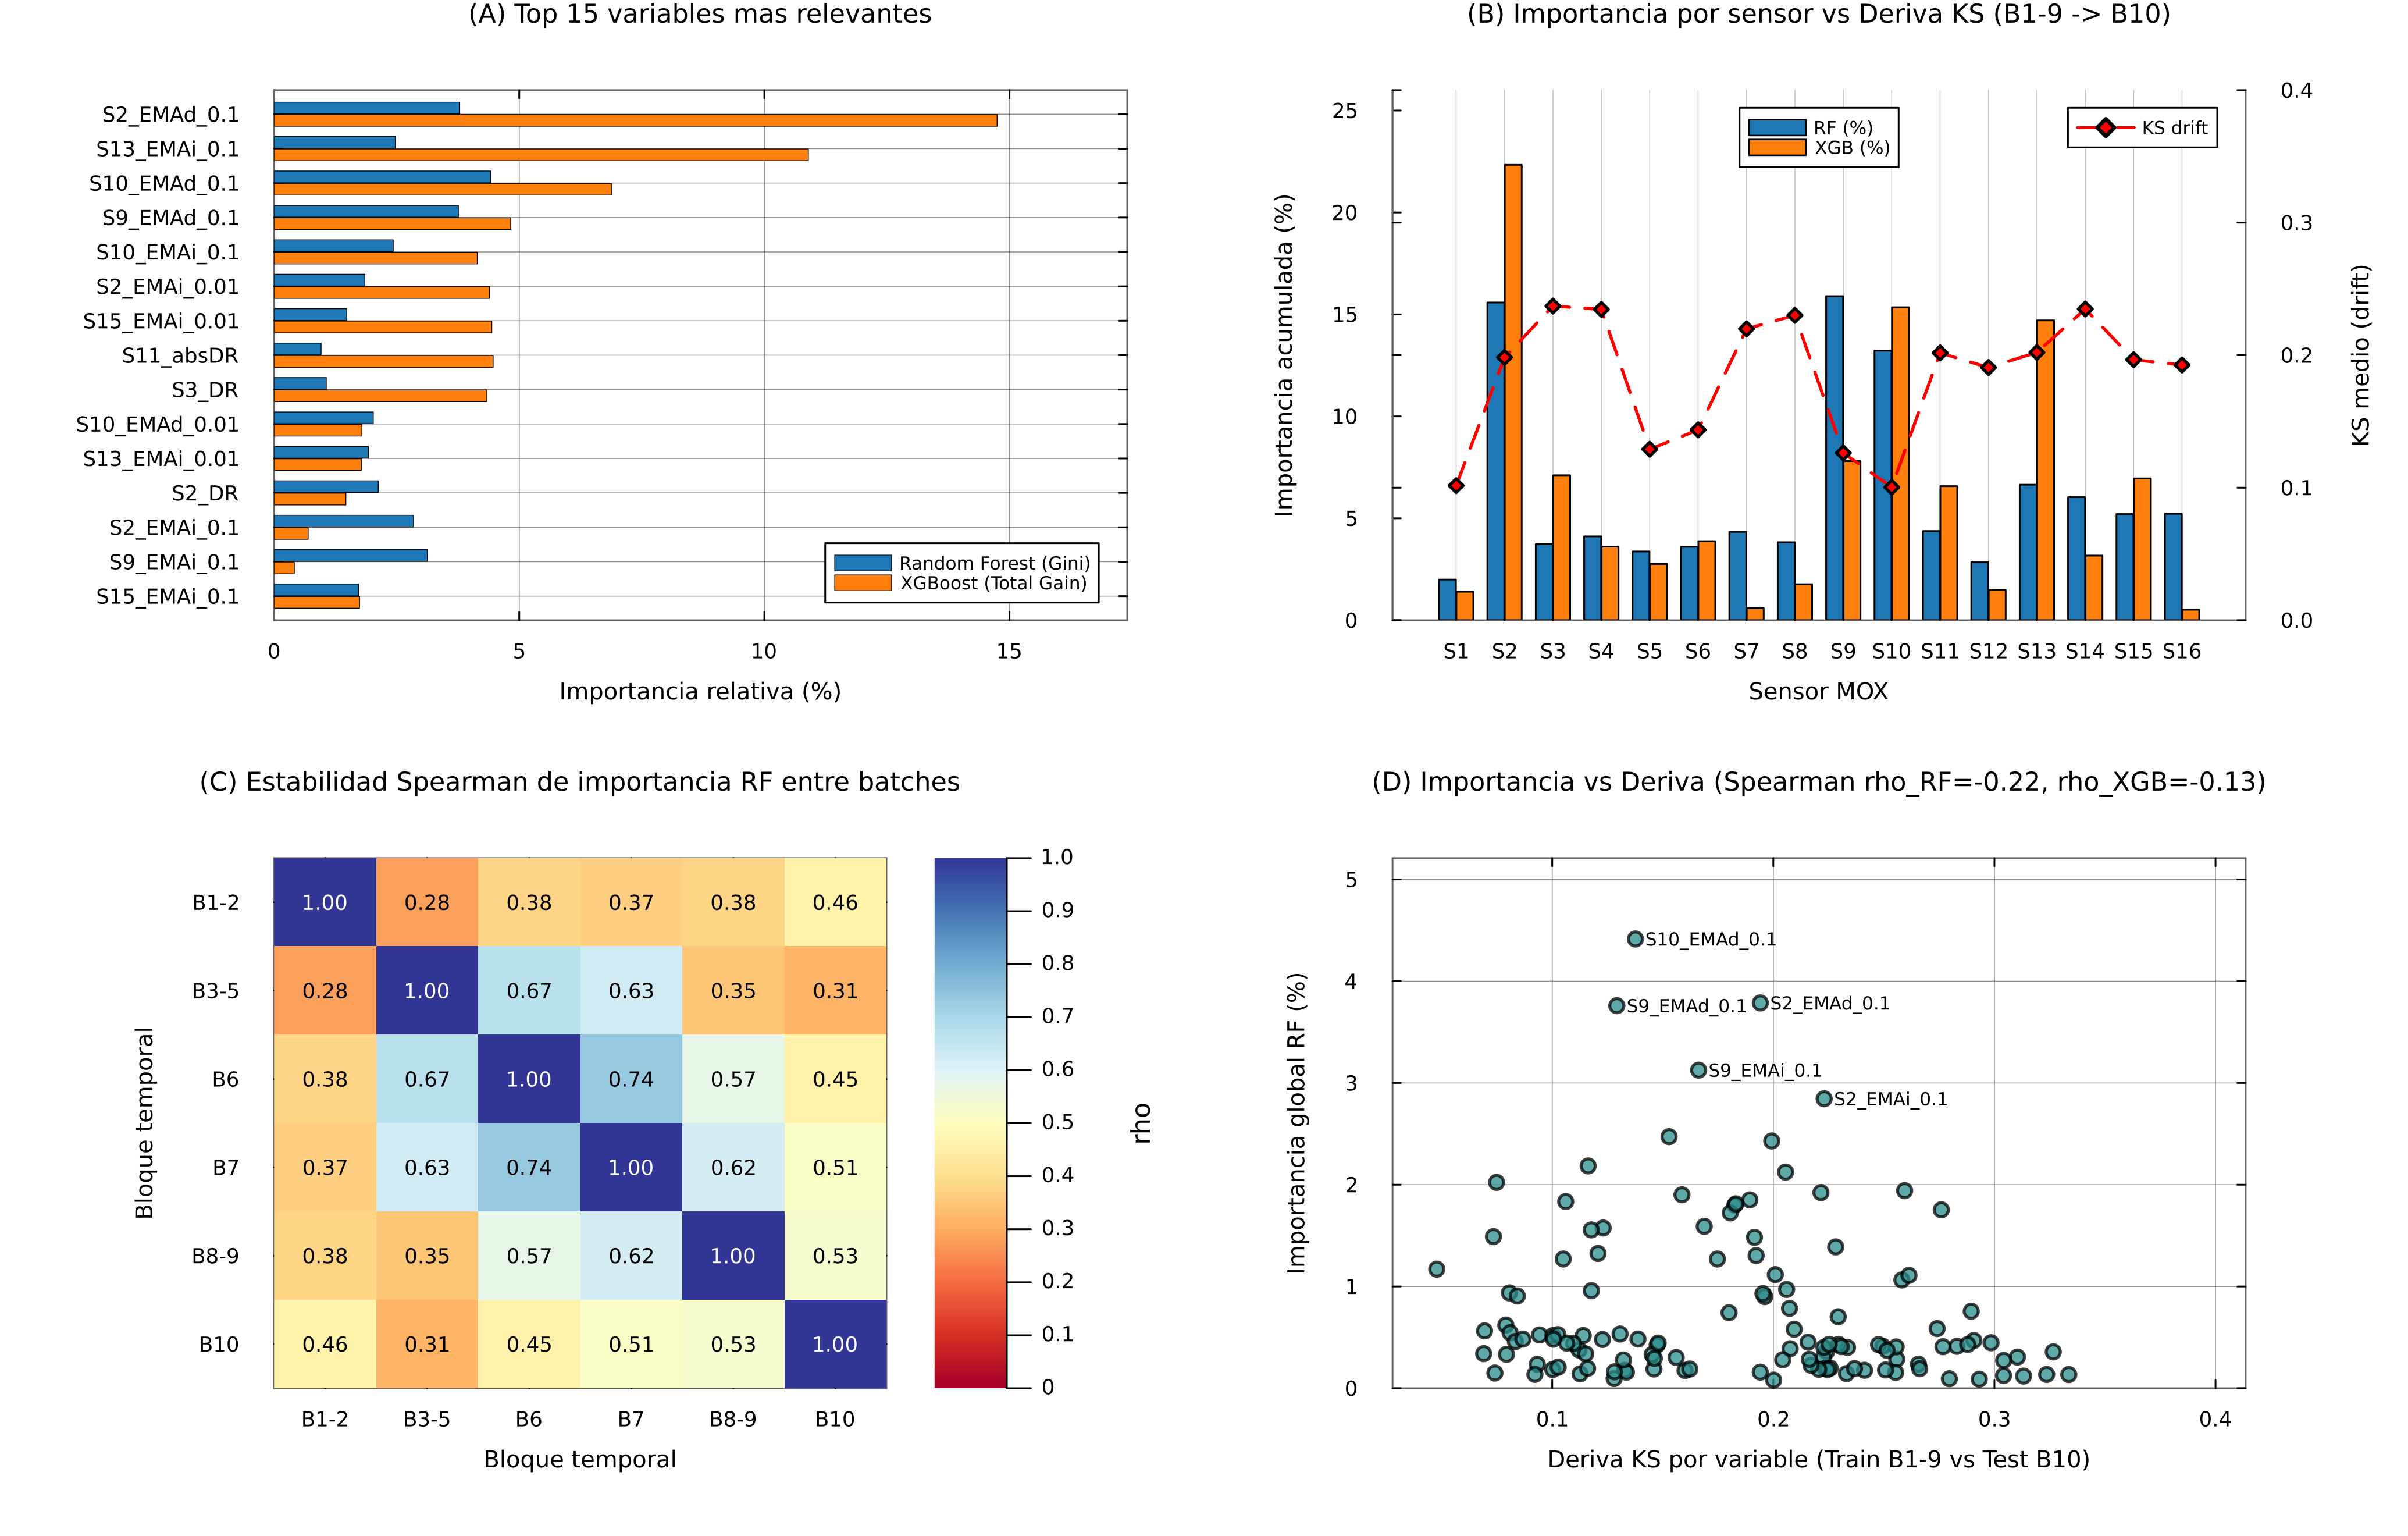

In [9]:
imp_res = run_feature_importance_and_stability(
    X_marked, classes, batches, holdout_split.train_idx, holdout_split.test_idx;
    scaler=PRIMARY_SCALER, seed=SEED
)
CSV.write(joinpath(RESULTS_DIR, "feature_importance_global.csv"), imp_res.feat_df)
CSV.write(joinpath(RESULTS_DIR, "sensor_importance_drift.csv"), imp_res.sensor_df)
CSV.write(joinpath(RESULTS_DIR, "feature_type_importance.csv"), imp_res.ftype_df)
CSV.write(joinpath(RESULTS_DIR, "importance_stability_rf_spearman.csv"), DataFrame(imp_res.rf_spearman, Symbol.(imp_res.block_names)))
CSV.write(joinpath(RESULTS_DIR, "importance_stability_xgb_spearman.csv"), DataFrame(imp_res.xgb_spearman, Symbol.(imp_res.block_names)))
plot_fig09_feature_importance_stability(imp_res, joinpath(FIGURES_DIR, "fig09_feature_importance_stability.png"))

println(@sprintf("Correlación Spearman RF vs XGBoost (128 vars): %.4f", imp_res.corr_rf_xgb))
println(@sprintf("Correlación Spearman Importancia RF vs Drift : %.4f", imp_res.corr_rf_drift))
println(@sprintf("Correlación Spearman Importancia XGB vs Drift: %.4f", imp_res.corr_xgb_drift))
display(first(sort(imp_res.feat_df, :rf_importance; rev=true), 12))
display("image/png", read(joinpath(FIGURES_DIR, "fig09_feature_importance_stability.png")))

**Conclusiones parciales (Fase 8):** Los transitorios dinámicos exponenciales ($EMAi$ y variación normalizada $|DR|$) acumulan mayor poder discriminante y estabilidad relativa que la resistencia bruta $DR$. No obstante, la matriz de correlación de Spearman entre bloques temporales evidencia rotación de importancias a medida que determinados sensores envejecen de forma heterogénea.

---
## 9. Contrastes Estadísticos sobre CV, Ablación Metodológica y Conclusiones Finales

1. **Test estadístico sobre los 5 folds emparejados de validación cruzada** (no se aplica sobre el *holdout* final al tratarse de una única evaluación puntual): ejecutamos el **Test no paramétrico de Friedman** ($\chi^2_F$) junto con la corrección exacta de **Iman–Davenport** ($F_F$), el test *post-hoc* de **Nemenyi** (Diferencia Crítica $CD$ a $\alpha = 0,05$), comparaciones por pares de **Wilcoxon Signed-Rank** ajustadas por **Holm–Bonferroni** y **ANOVA unifactorial** como referencia paramétrica.
2. **Ablación metodológica de validación:** cuantificamos empíricamente el sesgo optimista de una validación aleatoria estratificada convencional (que mezcla instancias del mismo *batch* entre entrenamiento y validación) frente a *GroupKFold* por bloques contiguos, nuestra validación **5-Fold Temporal Causal** y el rendimiento real en el *Holdout Test* (*Batch 10*).

Friedman Q = 22.1446 (p = 0.008432) | Iman-Davenport F = 3.8756 (p = 0.001646) | Nemenyi CD = 6.059


model,random_cv_mean,group_cv_mean,causal_cv_mean,holdout_b10_acc,optimism_gap_random_vs_test
SVM(C=1.0),0.7867,0.6395,0.5377,0.5303,0.2564
KNN(k=10),0.9872,0.8817,0.8241,0.5789,0.4083
MLP([100]),0.9861,0.8859,0.8091,0.8125,0.1736
"RF(500,d=10)",0.9930,0.8503,0.8009,0.6050,0.3880


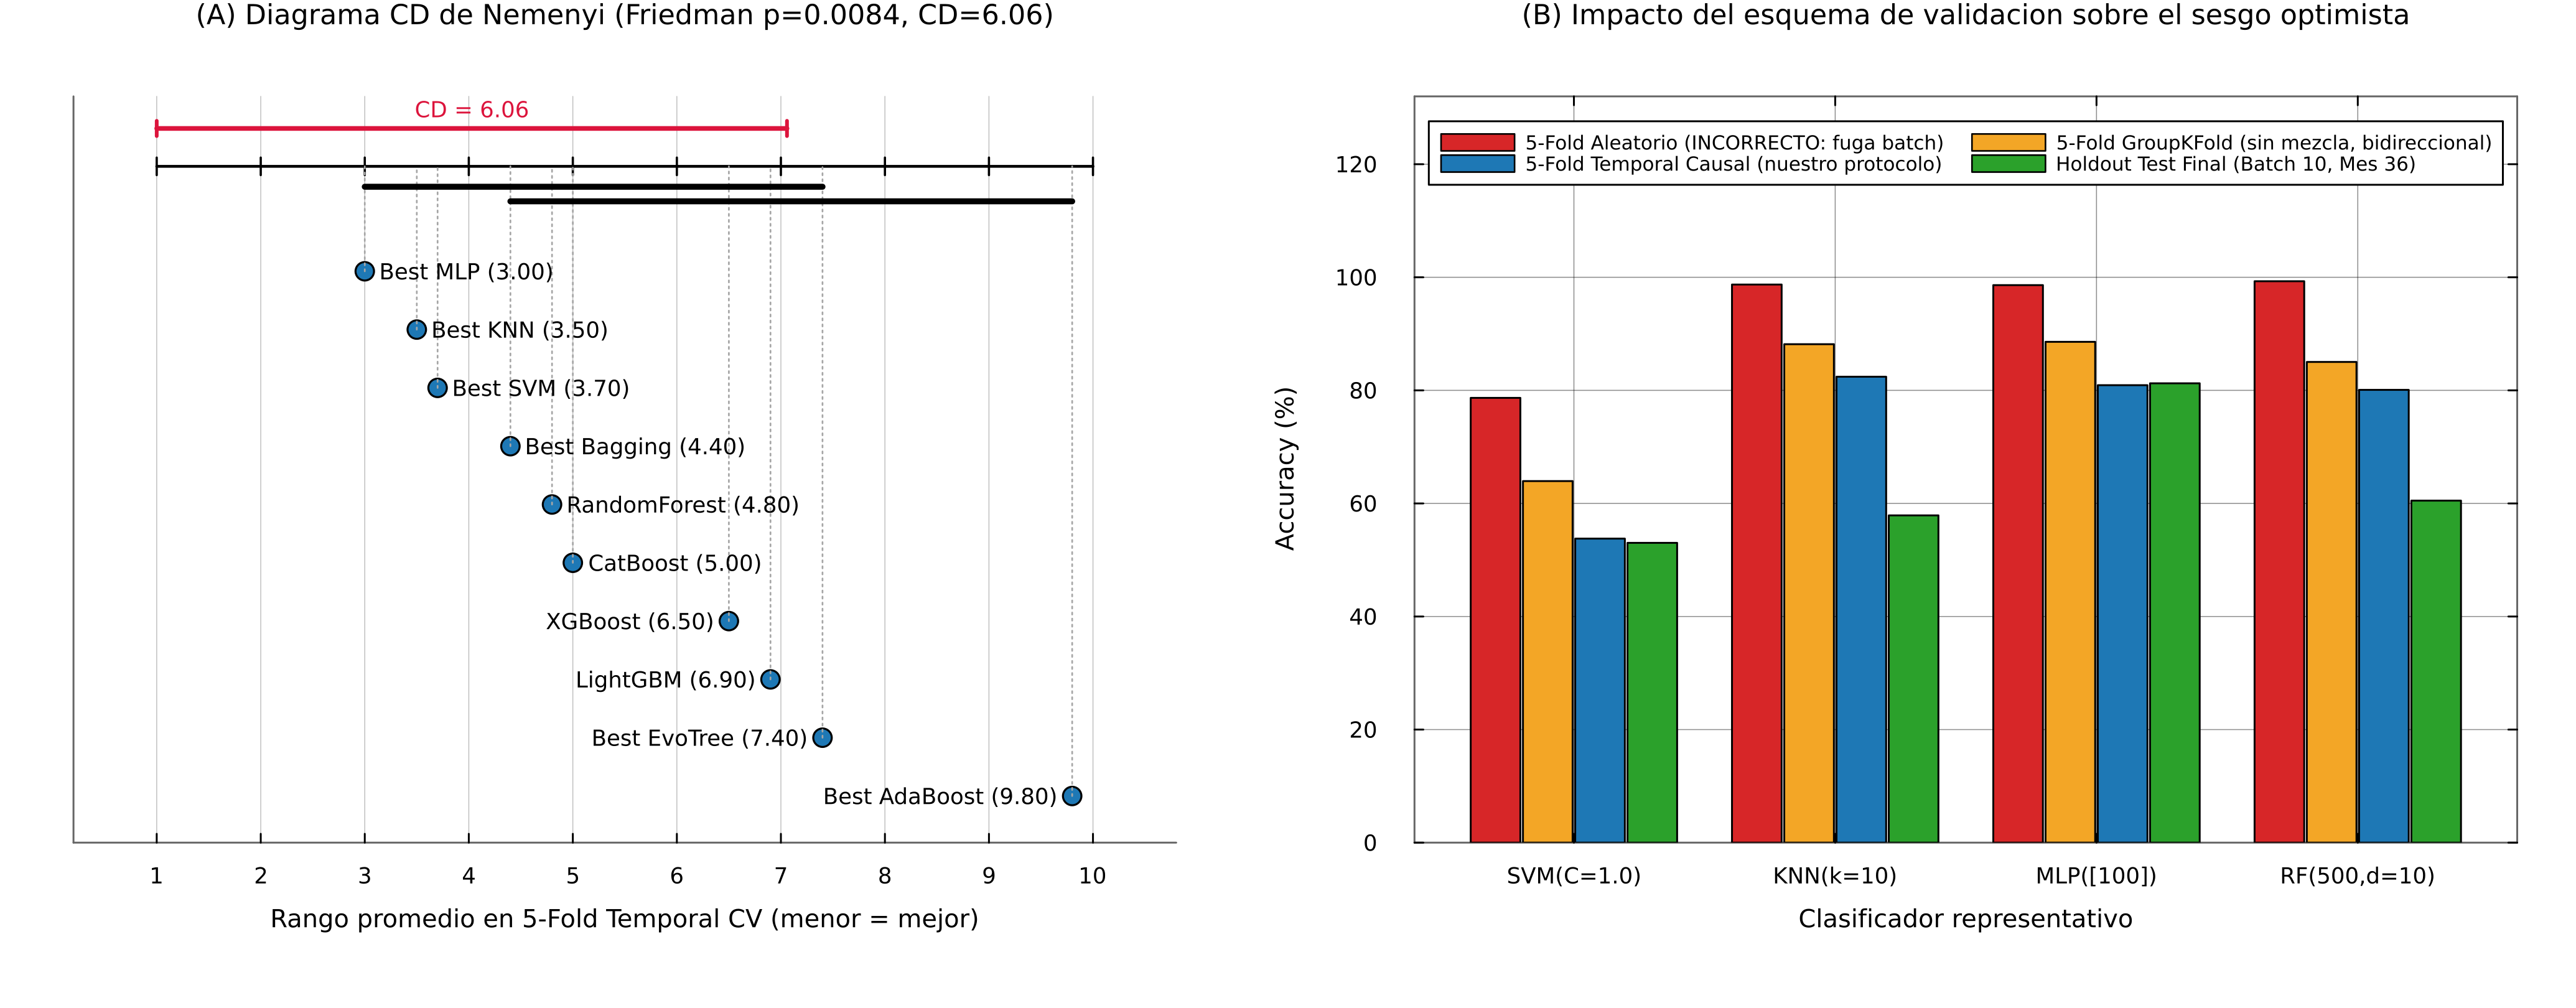

In [10]:
stat_models = [
    ("Best SVM",      best_svm_cv.fold_accs),
    ("Best KNN",      best_knn_cv.fold_accs),
    ("Best MLP",      best_mlp_cv.fold_accs),
    ("Best Bagging",  best_bag_cv.fold_accs),
    ("Best AdaBoost", best_ada_cv.fold_accs),
    ("Best EvoTree",  best_evo_cv.fold_accs),
    ("RandomForest",  rf_cv.fold_accs),
    ("XGBoost",       xgb_cv.fold_accs),
    ("LightGBM",      lgb_cv.fold_accs),
    ("CatBoost",      cat_cv.fold_accs),
]
stat_names = [m[1] for m in stat_models]
stat_vecs  = [m[2] for m in stat_models]
stat_res = run_statistical_tests(stat_names, stat_vecs)

CSV.write(joinpath(RESULTS_DIR, "stat_summary_cv.csv"), stat_res.summary_df)
CSV.write(joinpath(RESULTS_DIR, "stat_nemenyi_pairs.csv"), stat_res.nemenyi_pairs)
CSV.write(joinpath(RESULTS_DIR, "stat_wilcoxon_holm_pairs.csv"), stat_res.wilcoxon_pairs)

val_ablation_df = run_validation_methodology_ablation(
    Xtr, ytr, btr, Xte, yte, folds_causal; scaler=PRIMARY_SCALER
)
CSV.write(joinpath(RESULTS_DIR, "validation_ablation.csv"), val_ablation_df)
plot_fig10_statistical_cd_and_validation_ablation(
    stat_res, stat_names, val_ablation_df,
    joinpath(FIGURES_DIR, "fig10_statistical_cd_and_validation_ablation.png")
)

println(@sprintf("Friedman Q = %.4f (p = %.6f) | Iman-Davenport F = %.4f (p = %.6f) | Nemenyi CD = %.3f",
                 stat_res.friedman_stat, stat_res.friedman_p,
                 stat_res.iman_davenport_F, stat_res.iman_davenport_p, stat_res.cd))
display(val_ablation_df)
display("image/png", read(joinpath(FIGURES_DIR, "fig10_statistical_cd_and_validation_ablation.png")))

### Conclusiones Finales Integradas
1. **Rigor anti-leakage e impacto crítico del esquema de validación:** La validación aleatoria convencional sobreestima masivamente la capacidad de generalización (rozando el 99% por memorización del estado basal intra-*batch*), mientras que el esquema **5-Fold Temporal Causal** anticipa de forma realista la degradación que sufren los clasificadores al extrapolar sobre el *Batch 10* (Mes 36).
2. **Superioridad de métodos dinámicos, no lineales y de ensemble:** Las arquitecturas neuronales (`MLP`), ensembles heterogéneos (`Stacking`) y métodos de *Gradient Boosting* / *Bagging* mitigan parcialmente la deriva al combinar señales multi-sensor y dinámicas transitorias ($EMA$), superando ampliamente a clasificadores débiles de umbral rígido (`AdaBoost Stump`).
3. **Significación estadística:** El contraste de bloques de Friedman / Iman–Davenport sobre los 5 folds causales confirma diferencias globalmente significativas entre familias de clasificadores, identificando mediante la Diferencia Crítica de Nemenyi el grupo de modelos estadísticamente líderes.